In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy import stats
import matplotlib.dates as mdates
from sklearn.metrics import roc_auc_score


pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:.4f}".format)

sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)

ROOT = Path(".")
DATA_DIR = ROOT / "data"
TARGET = "target"

train = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["assignment_ts"])
test  = pd.read_csv(DATA_DIR / "test.csv",  parse_dates=["assignment_ts"])
events = pd.read_csv(DATA_DIR / "events.csv", parse_dates=["event_ts"])

train["assignment_date"] = pd.to_datetime(train["assignment_date"])
test["assignment_date"]  = pd.to_datetime(test["assignment_date"])

print("train :", train.shape)
print("test  :", test.shape)
print("events:", events.shape)

train : (13694, 119)
test  : (4306, 118)
events: (254705, 7)


In [ ]:
for name, df in [("train", train), ("test", test), ("events", events)]:
    print(f"\n{name}: {df.shape}")
    print(f"Числовых колонок  : {df.select_dtypes(include='number').shape[1]}")
    print(f"Категориальных    : {df.select_dtypes(include='object').shape[1]}")
    print(f"Колонок с пропуском: {(df.isna().sum() > 0).sum()}")


train: (13694, 119)
Числовых колонок  : 108
Категориальных    : 9
Колонок с пропуском: 97

test: (4306, 118)
Числовых колонок  : 107
Категориальных    : 9
Колонок с пропуском: 97

events: (254705, 7)
Числовых колонок  : 2
Категориальных    : 4
Колонок с пропуском: 0


## Выводы: структура данных

- `train`: 13 694 × 119, `test`: 4 306 × 118 (в test нет только `target`)
- `events`: 254 705 × 7 — пропуски отсутсвуют
- Соотношение num/cat = 108/9 — задача преимущественно числовая.
- 97 колонок имеют пропуски, дальше надо посмотреть на количество пропусков подробнее

In [ ]:
dup_summary = pd.DataFrame({
    "dataset": ["train", "test", "events"],
    "n_rows": [len(train), len(test), len(events)],
    "n_duplicate_rows": [
        train.duplicated().sum(),
        test.duplicated().sum(),
        events.duplicated().sum(),
    ],
})

dup_summary["pct_duplicate_rows"] = (
    100 * dup_summary["n_duplicate_rows"] / dup_summary["n_rows"]
)

display(dup_summary)

,dataset,n_rows,n_duplicate_rows,pct_duplicate_rows
0,train,13694,0,0.0000
1,test,4306,0,0.0000
2,events,254705,0,0.0000


In [ ]:
#Посчитаем процент пропусков
miss = (
    train.isna()
    .mean()
    .mul(100)
    .rename("pct_missing")
    .sort_values(ascending=False)
)
display(miss[miss > 0].to_frame().head(20))

miss = (
    test.isna()
    .mean()
    .mul(100)
    .rename("pct_missing")
    .sort_values(ascending=False)
)
display(miss[miss > 0].to_frame().head(20))

,pct_missing
seller_response_rate_30d,5.1701
leadgen_prev_positive_90d,3.3007
item_favorites_3d,3.2934
query_refinements_30d,3.2569
detail_expands_3d,3.2496
user_contacts_3d,3.1839
leadgen_prev_assigned_7d,3.1766
call_clicks_14d,3.1693
user_contacts_14d,3.1620
call_clicks_30d,3.1620


,pct_missing
seller_response_rate_30d,5.1556
user_contacts_30d,3.5532
saved_search_matches_1d,3.4603
similar_item_clicks_30d,3.4371
similar_item_clicks_7d,3.4138
saved_search_matches_7d,3.3674
search_views_30d,3.3209
call_clicks_3d,3.2977
leadgen_prev_assigned_3d,3.2745
leadgen_prev_answered_3d,3.2513


Колонок с пропусками: 97


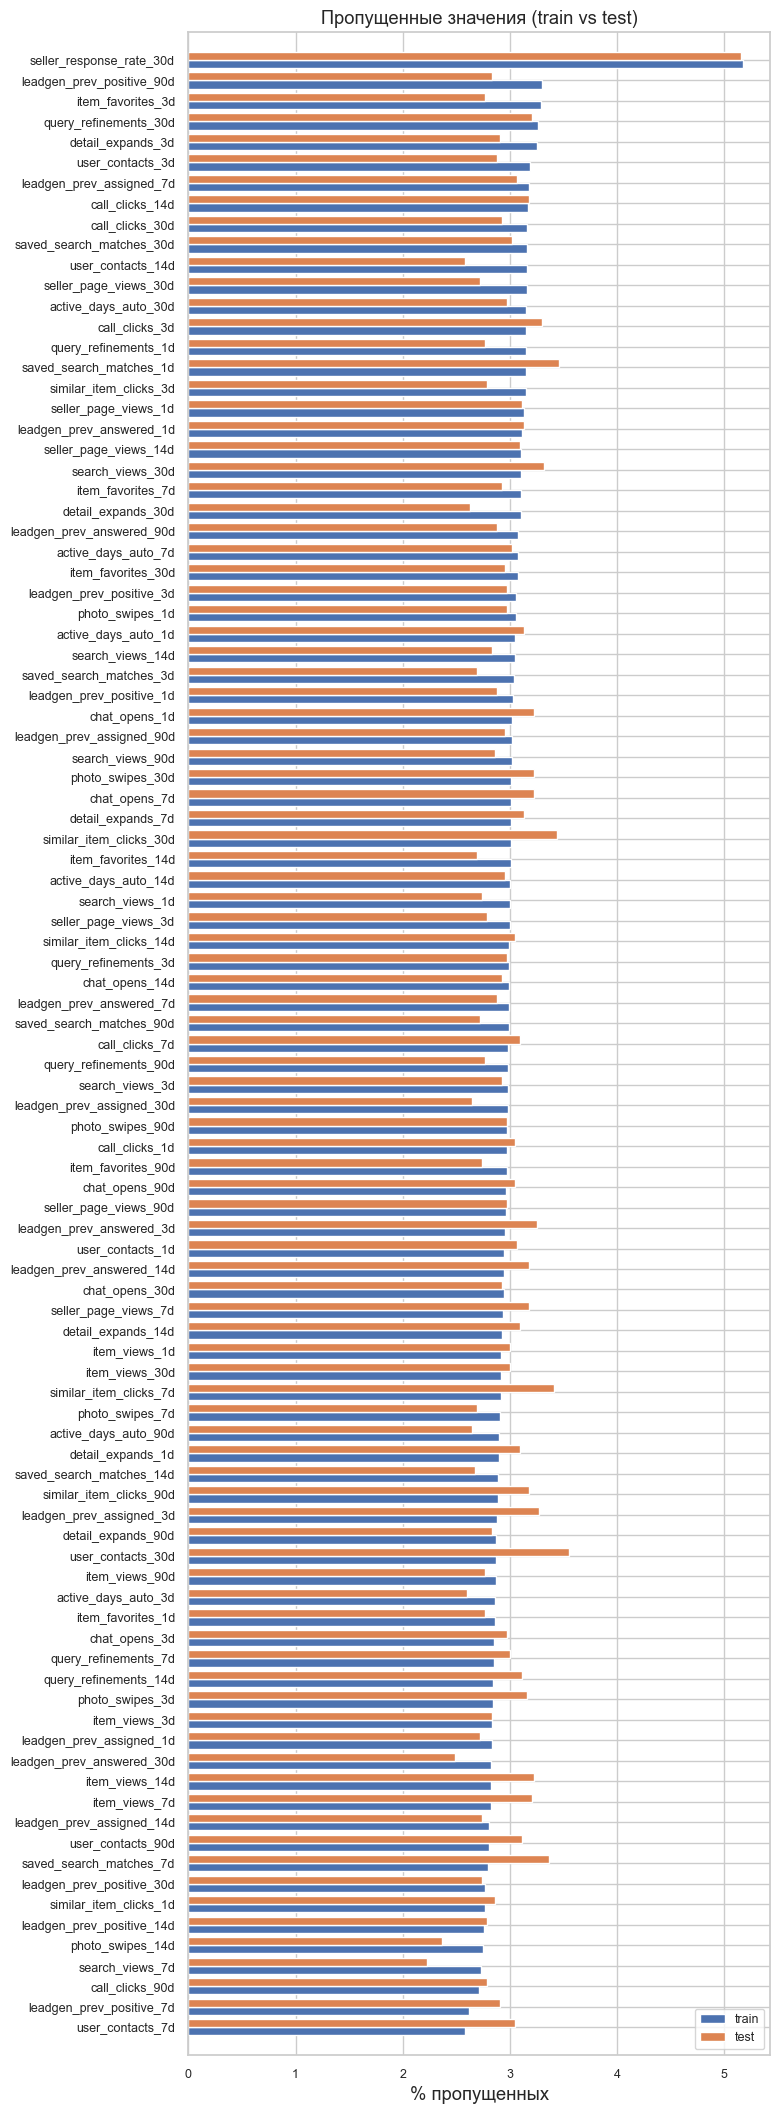

In [ ]:
miss_train = train.isna().mean().mul(100)
miss_test = test.isna().mean().mul(100)

miss_df = pd.DataFrame({"train": miss_train, "test": miss_test}).fillna(0)

# Оставляем только колонки, где есть пропуски хотя бы в одном из наборов
miss_df = miss_df[(miss_df["train"] > 0) | (miss_df["test"] > 0)]

# Сортируем по train
miss_df = miss_df.sort_values("train", ascending=False)

if len(miss_df) == 0:
    print("Пропусков нет ни в train, ни в test.")
else:
    print(f"Колонок с пропусками: {len(miss_df)}")

    fig, ax = plt.subplots(figsize=(8, max(3, len(miss_df) * 0.22)))

    y = np.arange(len(miss_df))
    height = 0.4

    # Реверс, чтобы наверху была колонка с наибольшим % пропусков в train
    features = miss_df.index[::-1]
    train_vals = miss_df["train"].values[::-1]
    test_vals = miss_df["test"].values[::-1]

    ax.barh(y - height / 2, train_vals, height=height, color="#4C72B0", label="train")
    ax.barh(y + height / 2, test_vals, height=height, color="#DD8452", label="test")

    ax.set_yticks(y)
    ax.set_yticklabels(features, fontsize=9)
    ax.set_xlabel("% пропущенных")
    ax.set_title("Пропущенные значения (train vs test)")
    ax.legend(loc="lower right", fontsize=9)
    ax.tick_params(axis="x", labelsize=9)
    ax.margins(y=0.01)

    plt.tight_layout()
    plt.show()

need_impute = miss_df.index.tolist()

- Максимальный уровень пропусков — 5.17% (`seller_response_rate_30d`).
- Пропуски равномерно распределены между train и test.

Все пропуски это окна, т.е. за данное окно не собралось данных для определенного user. При этом есть случаи когда за малое окно есть значение, а за большее стоит NaN, поэтому заполним таким образом, если счетчик заполним левым (коротким окном) если есть, иначе 0. Если это непрерывная величина возьмем среднее слева и справа.

Распределение таргета     : 0.2075
Отношение (0:1) : 3.82:1


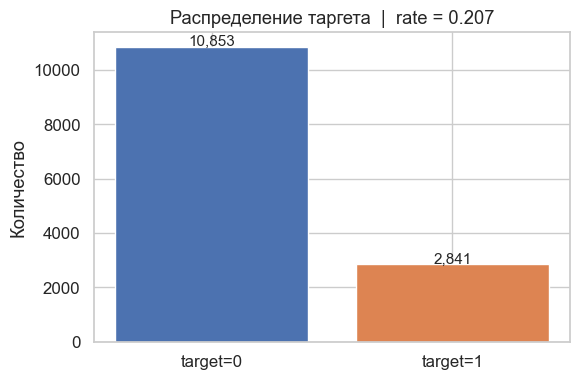

In [ ]:
target_counts = train[TARGET].value_counts()
target_rate   = train[TARGET].mean()
imbalance     = target_counts[0] / target_counts[1]

print(f"Распределение таргета     : {target_rate:.4f}")
print(f"Отношение (0:1) : {imbalance:.2f}:1")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["target=0", "target=1"], target_counts.values, color=["#4C72B0", "#DD8452"])
for i, v in enumerate(target_counts.values):
    ax.text(i, v + 30, f"{v:,}", ha="center", fontsize=11)
ax.set_title(f"Распределение таргета  |  rate = {target_rate:.3f}")
ax.set_ylabel("Количество")
plt.tight_layout()
plt.show()

- Target rate = 0.2075, дисбаланс = 3.82:1 — умеренный.

Как видим есть дисбалнс и конверсия маленькая, поэтому в дальнейшем будем добавлять больший вес позитивному классу, чтобы модель не переобучилась на мажорантный класс

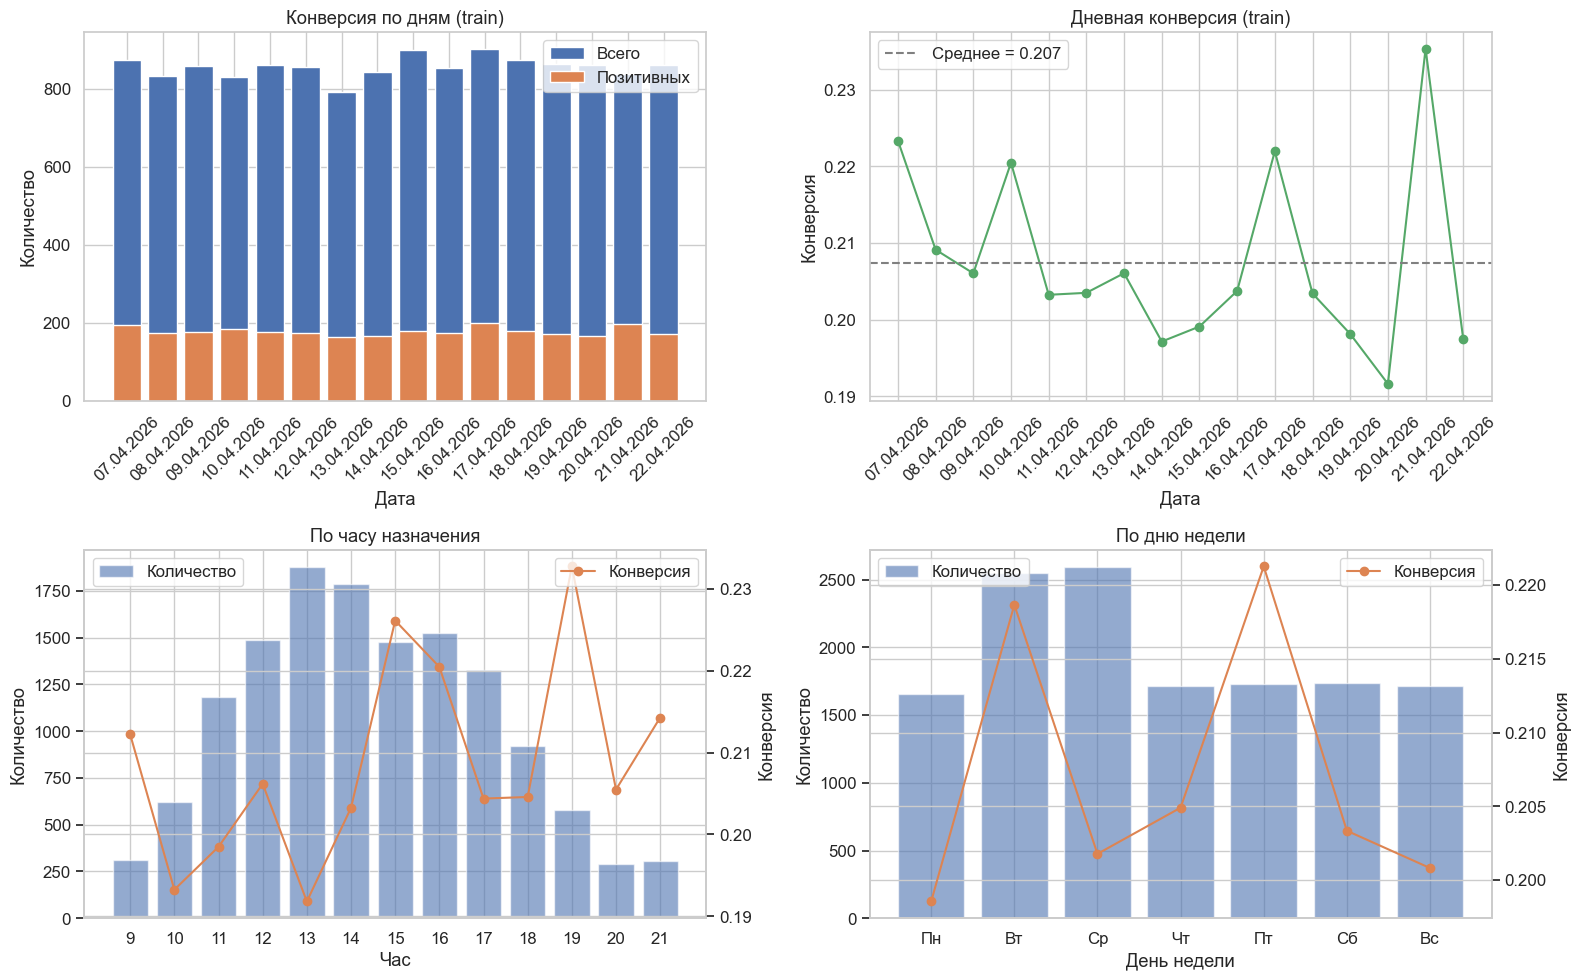

Период train  : 2026-04-07 — 2026-04-22
Период test   : 2026-04-23 — 2026-04-27
Период events : 2026-03-08 — 2026-04-27
Пересекающихся дат: 0


In [ ]:


fig, axes = plt.subplots(2, 2, figsize=(16, 10))


# Подсчет относительно таргет и времени некоторые характеристики
daily = (
    train.groupby("assignment_date")[TARGET]
    .agg(["count", "sum", "mean"])
    .rename(columns={"count": "total", "sum": "positives", "mean": "rate"})
    .reset_index()
    .sort_values("assignment_date")
)


date_fmt = mdates.DateFormatter("%d.%m.%Y")

#График количества таргета по дням
ax = axes[0, 0]
ax.bar(daily["assignment_date"], daily["total"], color="#4C72B0", label="Всего")
ax.bar(daily["assignment_date"], daily["positives"], color="#DD8452", label="Позитивных")
ax.set_title("Конверсия по дням (train)")
ax.set_xlabel("Дата")
ax.set_ylabel("Количество")
ax.legend()


ax.set_xticks(daily["assignment_date"])
ax.xaxis.set_major_formatter(date_fmt)
ax.tick_params(axis="x", rotation=45)

# Дневная конверсия таргета
ax = axes[0, 1]
ax.plot(daily["assignment_date"], daily["rate"], marker="o", color="#55A868")
ax.axhline(target_rate, linestyle="--", color="gray", label=f"Среднее = {target_rate:.3f}")
ax.set_title("Дневная конверсия (train)")
ax.set_xlabel("Дата")
ax.set_ylabel("Конверсия")
ax.legend()


ax.set_xticks(daily["assignment_date"])
ax.xaxis.set_major_formatter(date_fmt)
ax.tick_params(axis="x", rotation=45)

# Также но по часам
hourly = (
    train.groupby("assignment_hour")[TARGET]
    .agg(["count", "mean"])
    .reset_index()
    .sort_values("assignment_hour")
)

ax = axes[1, 0]
ax2 = ax.twinx()
ax.bar(hourly["assignment_hour"], hourly["count"], color="#4C72B0", alpha=0.6, label="Количество")
ax2.plot(hourly["assignment_hour"], hourly["mean"], color="#DD8452", marker="o", label="Конверсия")
ax.set_title("По часу назначения")
ax.set_xlabel("Час")
ax.set_ylabel("Количество")
ax2.set_ylabel("Конверсия")
ax.set_xticks(hourly["assignment_hour"])
ax.legend(loc="upper left")
ax2.legend(loc="upper right")

# По дню недели
dow_map = {0: "Пн", 1: "Вт", 2: "Ср", 3: "Чт", 4: "Пт", 5: "Сб", 6: "Вс"}
dow = (
    train.groupby("assignment_weekday")[TARGET]
    .agg(["count", "mean"])
    .reset_index()
    .sort_values("assignment_weekday")
)
dow["day"] = dow["assignment_weekday"].map(dow_map)

ax = axes[1, 1]
ax2 = ax.twinx()
ax.bar(dow["day"], dow["count"], color="#4C72B0", alpha=0.6, label="Количество")
ax2.plot(dow["day"], dow["mean"], color="#DD8452", marker="o", label="Конверсия")
ax.set_title("По дню недели")
ax.set_xlabel("День недели")
ax.set_ylabel("Количество")
ax2.set_ylabel("Конверсия")
ax.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.savefig("eda_temporal.png", dpi=150)
plt.show()

# Проверим: есть ли пересечение дат train и test
train_dates = set(train["assignment_date"].dt.date)
test_dates  = set(test["assignment_date"].dt.date)
overlap     = train_dates & test_dates

print(f"Период train  : {train['assignment_date'].min().date()} — {train['assignment_date'].max().date()}")
print(f"Период test   : {test['assignment_date'].min().date()} — {test['assignment_date'].max().date()}")
print(f"Период events : {events['event_ts'].min().date()} — {events['event_ts'].max().date()}")
print(f"Пересекающихся дат: {len(overlap)}")

- **Train:** 2026-04-07 - 2026-04-22 (16 дней).
- **Test:** 2026-04-23 - 2026-04-27 (5 дней), строго после train.
- **Events:** 2026-03-08 - 2026-04-27 (промежуток истории до train идущий до test включительно, поэтому надо при feature eng. аккуратно создавать новые признаки, обращая внимание на дату).
- Дневной объём стабильный ( около 800–900 назначений/день).
- Конверсия по дням колеблется в диапазоне 0.19–0.24.
- Активность максимальна в 13–16 ч; максимальная конверсия — в 19 ч.
- По дню недели: наибольший объём — вторник/среда, максимальная конверсия — пятница.

**Итого для обучения:**

При обучении random KFold нельзя делать, поэтому будем использовать расширяющее окно. Чтобы смоделировать условие будем оставлять gap в 5 дней.

**Итог для Feature Engineering:**

- Можно заметить, что в конце дня конверсия увеличивается, поэтому такие временные признаки будут полезны, можно к дополнению добавить признак `hour_bin` (night/morning/day/evening/late).
- Также можно добавить кодирование часа для линейных моделей (например sin/cos)



In [ ]:
# Сводная таблица по категориальным фичам
cat_cols = [c for c in train.columns
            if train[c].dtype == "object"
            and c not in {"lead_id", "user_id"}]

cat_rows = []
for col in cat_cols:
    vc     = train[col].value_counts(normalize=True, dropna=False)
    conv   = train.groupby(col)[TARGET].mean()
    cat_rows.append({
        "column"     : col,
        "n_unique"   : train[col].nunique(dropna=False),
        "top1_pct"   : round(vc.iloc[0] * 100, 1),
        "rare_pct"   : round(vc[vc < 0.01].sum() * 100, 1),
        "conv_min"   : round(conv.min(), 4),
        "conv_max"   : round(conv.max(), 4),
        "conv_std"   : round(conv.std(), 4),
    })

cat_summary = (
    pd.DataFrame(cat_rows)
    .sort_values("conv_std", ascending=False)
    .reset_index(drop=True)
)
display(cat_summary)

,column,n_unique,top1_pct,rare_pct,conv_min,conv_max,conv_std
0,lead_source,3,41.5000,0.0000,0.1476,0.2653,0.0592
1,call_center,2,57.6000,0.0000,0.1888,0.2328,0.0311
2,car_segment,4,42.2000,0.0000,0.1796,0.2362,0.0235
3,lead_channel,4,25.7000,0.0000,0.1936,0.2186,0.0114
4,region,5,20.4000,0.0000,0.2016,0.2125,0.0051
5,price_bucket,3,51.7000,0.0000,0.2059,0.2112,0.0027
6,user_tenure_bucket,3,45.1000,0.0000,0.2063,0.2089,0.0013


- Кардинальность у всех категориальных низкая (≤5). Поэтому можно обойтись One-hot encoding
- Конверсия есть, но небольшая, но категориальные признаки могут сильнее описываться в совокупности. Поэтому в Feature eng. можно добавить их кроссы.

- Для деревьев это не обязательно, так как они делают это нативно, но для линейных моделей это важно.

In [ ]:
num_cols = [
    c for c in train.select_dtypes(include=np.number).columns
    if c not in {"lead_id", TARGET, "assignment_hour", "assignment_weekday", "is_weekend"}
]

desc = train[num_cols].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
desc["skew"]     = train[num_cols].skew()
desc["pct_zero"] = (train[num_cols] == 0).mean() * 100
desc["pct_miss"] = train[num_cols].isna().mean() * 100

# Отсортируем по асимметрии
display(
    desc[["mean", "std", "min", "1%", "50%", "99%", "max",
          "skew"]]
    .sort_values("skew", ascending=False)
)

,mean,std,min,1%,50%,99%,max,skew
leadgen_prev_positive_1d,0.0130,0.1151,0.0000,0.0000,0.0000,1.0000,2.0000,9.0572
leadgen_prev_answered_1d,0.0174,0.1325,0.0000,0.0000,0.0000,1.0000,2.0000,7.6699
leadgen_prev_positive_3d,0.0163,0.1265,0.0000,0.0000,0.0000,1.0000,1.0000,7.6481
leadgen_prev_positive_7d,0.0302,0.1747,0.0000,0.0000,0.0000,1.0000,2.0000,5.8236
leadgen_prev_assigned_1d,0.0381,0.1976,0.0000,0.0000,0.0000,1.0000,3.0000,5.3448
...,...,...,...,...,...,...,...,...
user_active_days_30d,12.3830,5.2439,0.0000,3.0000,12.0000,28.0000,36.0000,0.7202
car_age_years,4.6159,2.7179,0.0000,0.0000,4.5200,11.1082,14.5440,0.2652
seller_response_rate_30d,0.4581,0.1742,0.0419,0.1146,0.4531,0.8375,0.9611,0.1276
item_price_log,12.9157,0.5939,11.1989,11.6379,12.9207,14.2573,14.9272,0.0706


In [ ]:
corr_target = (
    train[num_cols + [TARGET]]
    .corr()[TARGET]
    .drop(TARGET)
    .sort_values(key=abs, ascending=False)
)

# Таблица топ-20
display(corr_target.head(20).to_frame(name="pearson_corr_with_target"))

,pearson_corr_with_target
search_views_90d,0.2723
item_views_90d,0.2651
item_views_30d,0.2534
search_views_30d,0.2511
item_views_14d,0.2510
photo_swipes_30d,0.2497
search_views_14d,0.2411
active_days_auto_90d,0.2359
user_active_days_30d,0.2321
item_favorites_90d,0.2310



- Наибольший сигнал несут **длинные окна активности пользователя (14/30/90d)**:  
  `search_views_90d`, `item_views_90d`, `photo_swipes_30d`, `active_days_auto_90d`.
- Короткие окна (1d, 3d) слабее и разрежены. Это можно объяснить, тем что одно действие может быть случайным и шумом, но если пользователь заинтересован, то это будет отражаться на более долгом временном промежутке.
- Заметим что данные скошены (skew > 0) в дальнейшем для линейных моделей их надо привести к более нормальному распределению.


In [ ]:
# Корреляция между признаками
corr_matrix = train[num_cols].corr().abs()

high_corr_pairs = [
    {"feature_1": corr_matrix.columns[i],
     "feature_2": corr_matrix.columns[j],
     "abs_corr" : round(corr_matrix.iloc[i, j], 4)}
    for i in range(len(corr_matrix.columns))
    for j in range(i + 1, len(corr_matrix.columns))
    if corr_matrix.iloc[i, j] > 0.85
]

high_corr_df = (
    pd.DataFrame(high_corr_pairs)
    .sort_values("abs_corr", ascending=False)
)

print(f"Пар с |corr| > 0.85: {len(high_corr_df)}")
display(high_corr_df.head(20))

Пар с |corr| > 0.85: 27


,feature_1,feature_2,abs_corr
10,item_views_90d,photo_swipes_90d,0.9338
12,item_views_90d,search_views_90d,0.9297
21,photo_swipes_90d,search_views_90d,0.9218
3,item_views_30d,item_views_90d,0.9138
4,item_views_30d,photo_swipes_90d,0.9034
6,item_views_30d,search_views_90d,0.8991
14,item_views_90d,similar_item_clicks_90d,0.8900
23,photo_swipes_90d,similar_item_clicks_90d,0.8899
11,item_views_90d,search_views_30d,0.8840
26,search_views_90d,similar_item_clicks_90d,0.8804



Смотря на корреляцию между признаками, то видно сильная корреляция длинных окон связанные с событиями, что можно объяснить тем, что если человек заинтересован, то он скорее всего не только уже отсмотрел item, но и посмотрел все остальное, что с ним связано. Мультиколленеарность очень сильно вредит линейным моделям, поэтому после создания новых признаков надо убрать их, оставляя которые сильнее всего описывают таргет.

Размер events: (254705, 7)

Типы событий:
event_type
item_view     120905
search         61101
favorite       26333
chat_open      24797
call_click     21569
Name: count, dtype: int64


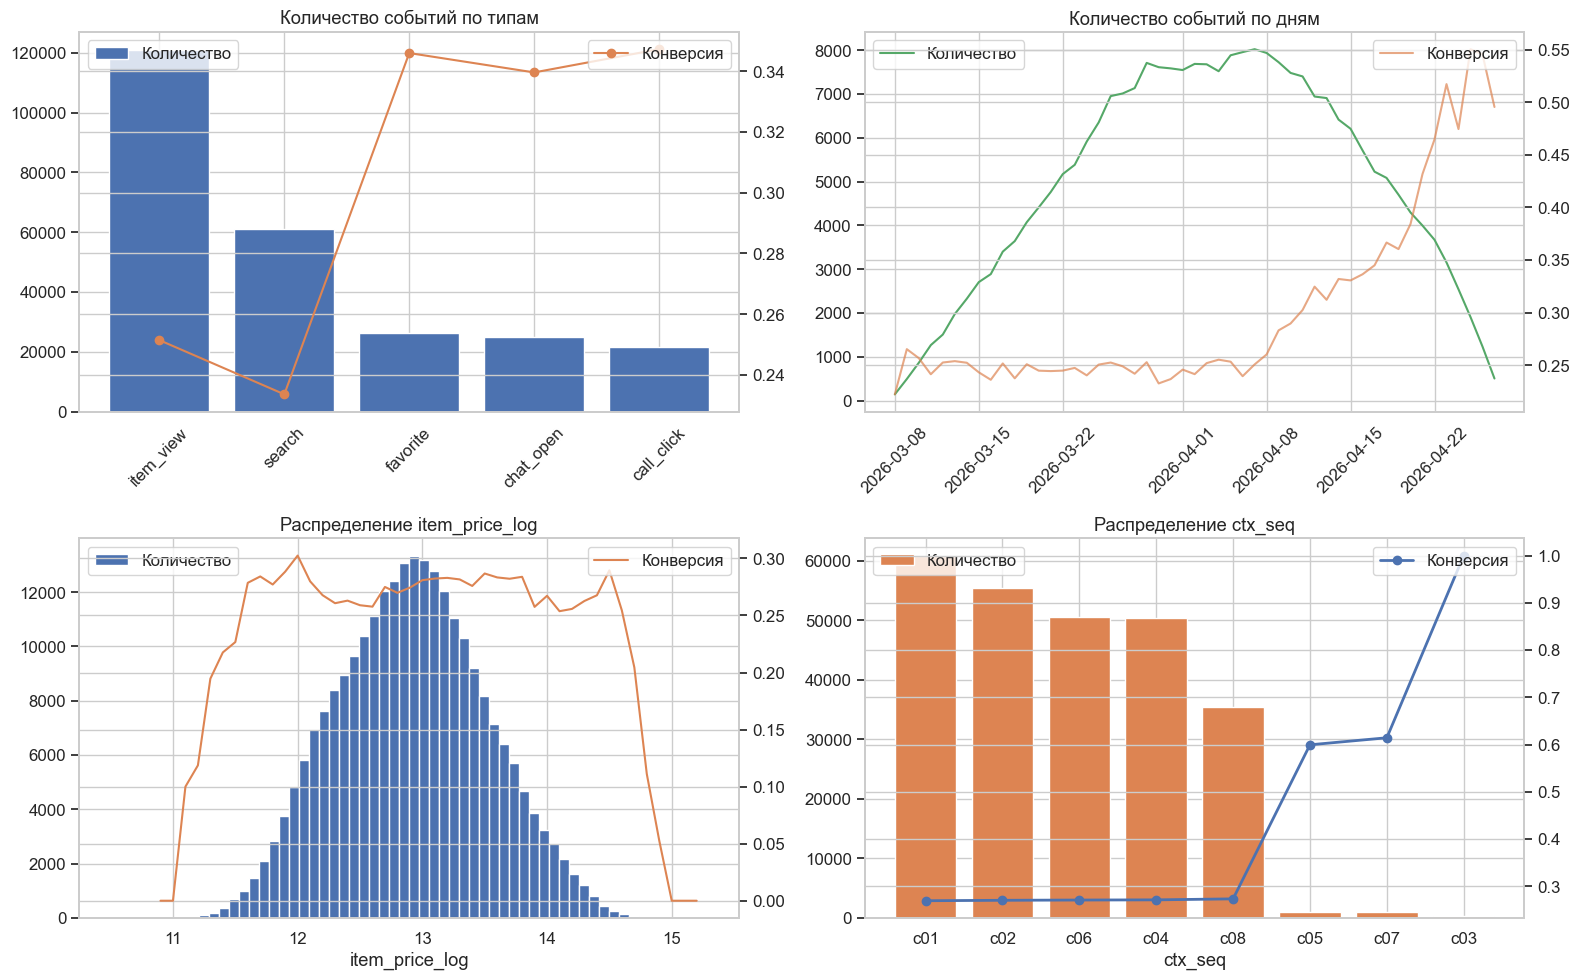

In [ ]:
print("Размер events:", events.shape)
print("\nТипы событий:")
print(events["event_type"].value_counts())

# возьмем TARGET для расчета конверсии
events_plot = events.merge(train[["lead_id", TARGET]].drop_duplicates(), on="lead_id", how="left")

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# Количество событий по типам
vc_et = events_plot["event_type"].value_counts()
rate_et = events_plot.groupby("event_type")[TARGET].mean().loc[vc_et.index]

ax = axes[0, 0]
ax2 = ax.twinx()
ax.bar(vc_et.index.astype(str), vc_et.values, color="#4C72B0", label="Количество")
ax2.plot(vc_et.index.astype(str), rate_et.values, color="#DD8452", marker="o", label="Конверсия")

ax.set_title("Количество событий по типам")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper left")
ax2.legend(loc="upper right")

# Количество событий по дате
events_plot["event_date"] = events_plot["event_ts"].dt.normalize()
daily_ev = events_plot.groupby("event_date").agg(count=("event_ts", "size"), rate=(TARGET, "mean")).reset_index()

ax = axes[0, 1]
ax2 = ax.twinx()
ax.plot(daily_ev["event_date"], daily_ev["count"], color="#55A868", label="Количество")
ax2.plot(daily_ev["event_date"], daily_ev["rate"], color="#DD8452", alpha=0.7, label="Конверсия")

ax.set_title("Количество событий по дням")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper left")
ax2.legend(loc="upper right")

# Распределение item_price_log
ax = axes[1, 0]
ax2 = ax.twinx()
ax.hist(events_plot["item_price_log"].dropna(), bins=60, color="#4C72B0", edgecolor="white", label="Количество")


price_rate = events_plot.groupby(events_plot["item_price_log"].round(1))[TARGET].mean()
ax2.plot(price_rate.index, price_rate.values, color="#DD8452", label="Конверсия")

ax.set_title("Распределение item_price_log")
ax.set_xlabel("item_price_log")
ax.legend(loc="upper left")
ax2.legend(loc="upper right")

# 12.4 Распределение ctx_seq
ax = axes[1, 1]
ax2 = ax.twinx()

# Считаем количество и конверсию по категориям
ctx_stats = (
    events_plot.groupby("ctx_seq")
    .agg(count=(TARGET, "size"), rate=(TARGET, "mean"))
    .sort_values("count", ascending=False)
)

x = ctx_stats.index.astype(str)

ax.bar(x, ctx_stats["count"], color="#DD8452", edgecolor="white", label="Количество")
ax2.plot(x, ctx_stats["rate"], color="#4C72B0", marker="o", linewidth=2, label="Конверсия")

ax.set_title("Распределение ctx_seq")
ax.set_xlabel("ctx_seq")
ax.legend(loc="upper left")
ax2.legend(loc="upper right")

plt.tight_layout()
plt.savefig("eda_events.png", dpi=150)
plt.show()

In [ ]:
# сколько лидов из train/test имеют события
train_leads_with_events = events["lead_id"].isin(train["lead_id"]).sum()
test_leads_with_events  = events["lead_id"].isin(test["lead_id"]).sum()
unique_event_leads      = events["lead_id"].nunique()

print(f"Всего уникальных lead_id в events: {unique_event_leads:,}")
print(f"Из train имеют события: {train['lead_id'].isin(events['lead_id']).mean():.1%}")
print(f"Из test  имеют события: {test['lead_id'].isin(events['lead_id']).mean():.1%}")
# Конверсия по наличию событий
has_events = train["lead_id"].isin(events["lead_id"])
print("Конверсия с событиями   :", train.loc[has_events, TARGET].mean().round(4))
print("Конверсия без событий   :", train.loc[~has_events, TARGET].mean().round(4))

Всего уникальных lead_id в events: 17,988
Из train имеют события: 99.9%
Из test  имеют события: 99.9%
Конверсия с событиями   : 0.2076
Конверсия без событий   : 0.0


- 99.9% лидов в train и test имеют события.
- Конверсия без событий = 0.0 — но таких лидов почти нет, но если такой случай появится можно сразу сказать, что целевое не выполнится, что и логично пользователь вообще не заинтересован. По хорошему можно добавить признак "Было ли событие".
- `item_price_log` в events нормально распределён (11–15), выбросов нет. При этом конверсия выше всего у среднего значения.
- `ctx_seq` — категориальная (значения c01–c08), несколько доминирующих, которые явно отражают конверсию. Скорее всего использование этого признака и его производных сильно скажется на метрике в положительную сторону.

In [ ]:
# Посмотрим есть ли сдвиг между train и test
shift_rows = []
for col in num_cols:
    if col not in test.columns:
        continue
    tr = train[col].dropna()
    te = test[col].dropna()
    ks_stat, ks_pval = stats.ks_2samp(tr, te)
    shift_rows.append({
        "column"    : col,
        "train_mean": round(tr.mean(), 4),
        "test_mean" : round(te.mean(), 4),
        "ks_stat"   : round(ks_stat, 4),
        "ks_pval"   : round(ks_pval, 6),
        "significant": ks_pval < 0.05,
    })

shift_df = (
    pd.DataFrame(shift_rows)
    .sort_values("ks_stat", ascending=False)
    .reset_index(drop=True)
)

sig_count = shift_df["significant"].sum()
print(f"Фичей со значимым сдвигом (p < 0.05): {sig_count} из {len(shift_df)}")
display(shift_df.head(15))

Фичей со значимым сдвигом (p < 0.05): 1 из 104


,column,train_mean,test_mean,ks_stat,ks_pval,significant
0,car_age_years,4.6159,4.4533,0.0347,0.0007,True
1,seller_page_views_30d,1.9723,2.0242,0.0205,0.1373,False
2,query_refinements_90d,14.0631,14.1168,0.0192,0.1908,False
3,detail_expands_90d,12.7471,12.9101,0.0184,0.2283,False
4,chat_opens_30d,2.0003,2.0397,0.0181,0.2454,False
5,seller_inventory_count,17.4664,17.8528,0.0176,0.2574,False
6,user_age_days,415.8997,410.5634,0.0175,0.2641,False
7,active_days_auto_30d,4.1859,4.2025,0.0167,0.3346,False
8,mileage_km_log,10.9858,10.9775,0.0164,0.3366,False
9,photo_swipes_7d,3.6258,3.6709,0.0162,0.3667,False


- Только 1 фича со статистически значимым сдвигом:  
  `car_age_years` (KS = 0.035, p = 0.0007).  
  Разница средних маленькая (4.62 vs 4.45) — не критично.
- Все остальные фичи стабильны между train и test.


- Data drift отсутствует
- Adversarial validation не нужна.
- Модель, обученная на всём train, должна хорошо переносится на test.
- Специальная коррекция под drift не требуется.

In [ ]:
# Посчитаем значения где 1 значение практически везде
all_cols = (
    [c for c in train.select_dtypes(include="number").columns
     if c not in {"lead_id", TARGET}]
    + [c for c in train.select_dtypes(include="object").columns
       if c not in {"lead_id"}]
)

quasi_rows = []
for col in all_cols:
    vc      = train[col].value_counts(normalize=True, dropna=False)
    top_val = vc.index[0] if len(vc) > 0 else None
    top_freq = float(vc.iloc[0]) if len(vc) > 0 else 1.0

    quasi_rows.append({
        "column"   : col,
        "top_value": str(top_val),
        "top_freq" : round(top_freq * 100, 2),
        "n_unique" : train[col].nunique(dropna=False),
        "is_const" : top_freq >= 1.0,
        "is_quasi" : top_freq >= 0.95,
    })

quasi_df = (
    pd.DataFrame(quasi_rows)
    .sort_values("top_freq", ascending=False)
    .reset_index(drop=True)
)

n_const = quasi_df["is_const"].sum()
n_quasi = quasi_df["is_quasi"].sum()

print(f"Константных фичей    : {n_const}")
print(f"Квази-константных    : {n_quasi}  (>= 95% одно значение)")

if n_quasi > 0:
    display(quasi_df[quasi_df["is_quasi"]])
else:
    print("Квази-константных нет.")

Константных фичей    : 0
Квази-константных    : 3  (>= 95% одно значение)


,column,top_value,top_freq,n_unique,is_const,is_quasi
0,leadgen_prev_positive_1d,0.0,95.7400,4,False,True
1,leadgen_prev_positive_3d,0.0,95.3700,3,False,True
2,leadgen_prev_answered_1d,0.0,95.2200,4,False,True



- 3 квази-константные фичи (одно значение встречается в >95% строк):
  - `leadgen_prev_positive_1d` — 95.74%
  - `leadgen_prev_positive_3d` — 95.37%
  - `leadgen_prev_answered_1d` — 95.22%
- естественная редкость события за короткие окна (1–3 дня).

Можно дропнуть или заменить все редкие значения на одно общее.

In [ ]:
# Посмотрим на выбросы
num_cols_for_outliers = [
    c for c in train.select_dtypes(include="number").columns
    if c not in {"lead_id", TARGET, "assignment_hour", "assignment_weekday", "is_weekend"}
    and train[c].std() > 0
]

out_rows = []
for col in num_cols_for_outliers:
    s   = train[col].dropna()
    q1  = s.quantile(0.25)
    q3  = s.quantile(0.75)
    iqr = q3 - q1
    # Посмотрим только на экстремальные выбросы
    lb  = q1 - 3.0 * iqr
    ub  = q3 + 3.0 * iqr

    n_out = int(((s < lb) | (s > ub)).sum())

    out_rows.append({
        "column"      : col,
        "p01"         : round(s.quantile(0.01), 4),
        "p99"         : round(s.quantile(0.99), 4),
        "max"         : round(s.max(), 4),
        "upper_bound" : round(ub, 4),
        "n_outliers"  : n_out,
        "pct_outliers": round(100 * n_out / len(s), 2),
    })

out_df = (
    pd.DataFrame(out_rows)
    .sort_values("pct_outliers", ascending=False)
    .reset_index(drop=True)
)


out_with = out_df[out_df["n_outliers"] > 0]
print(f"Фичей с выбросами (3*IQR): {len(out_with)} из {len(out_df)}")
display(out_with.head(20))

Фичей с выбросами (3*IQR): 99 из 104


,column,p01,p99,max,upper_bound,n_outliers,pct_outliers
0,item_favorites_3d,0.0000,2.0000,5.0000,0.0000,3206,24.2100
1,leadgen_prev_assigned_7d,0.0000,2.0000,5.0000,0.0000,2970,22.4000
2,user_contacts_3d,0.0000,2.0000,5.0000,0.0000,2815,21.2300
3,similar_item_clicks_1d,0.0000,2.0000,3.0000,0.0000,2447,18.3800
4,saved_search_matches_3d,0.0000,2.0000,4.0000,0.0000,2349,17.6900
5,seller_page_views_3d,0.0000,2.0000,4.0000,0.0000,2314,17.4200
6,chat_opens_3d,0.0000,2.0000,4.0000,0.0000,2285,17.1800
7,leadgen_prev_answered_14d,0.0000,2.0000,4.0000,0.0000,2156,16.2200
8,call_clicks_3d,0.0000,2.0000,3.0000,0.0000,1899,14.3200
9,query_refinements_1d,0.0000,2.0000,3.0000,0.0000,1875,14.1400


- Топ фичей по доле "выбросов" (3·IQR) — это разреженные счётчики,  
  где `Q1 = Q3 = 0`, поэтому любой ненулевой отсчёт формально считается выбросом.
- Реальных аномалий в данных нет: максимумы у счётчиков находятся в разумных диапазонах  
- 3·IQR метрика для разреженных счётчиков не показательна.

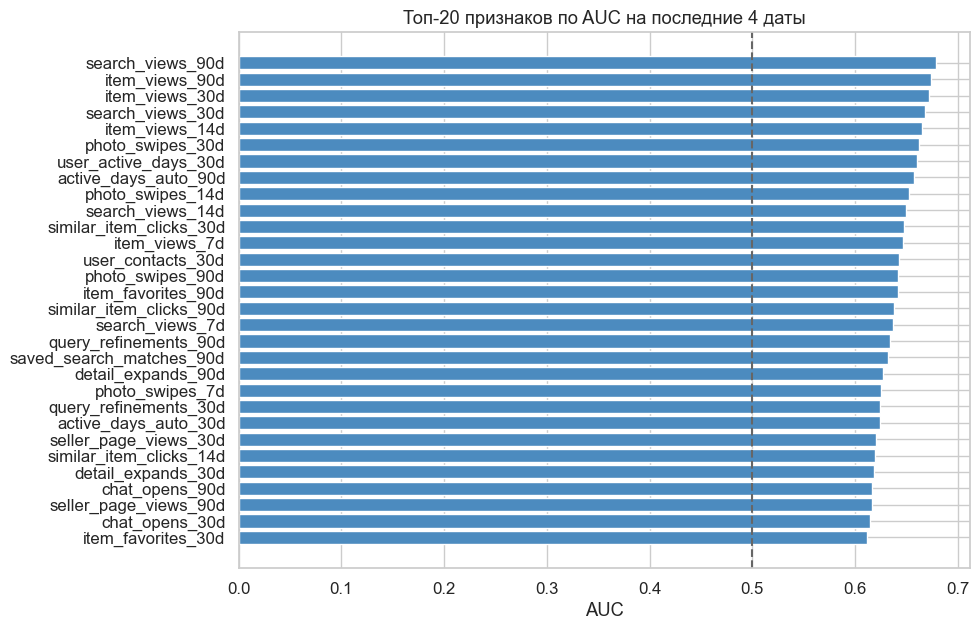

In [ ]:


# Числовые признаки 
numeric_columns_raw = [
    c for c in train.select_dtypes(include=[np.number]).columns
    if c != TARGET
]

# Последние 4 даты для валидации
latest_dates = sorted(train["assignment_date"].unique())[-4:]
valid_mask_eda = train["assignment_date"].isin(latest_dates)

univariate_rows = []
for column in numeric_columns_raw:
    median = train.loc[~valid_mask_eda, column].median()
    values = train.loc[valid_mask_eda, column].fillna(median)
    if values.nunique() < 2:
        continue
    auc = roc_auc_score(train.loc[valid_mask_eda, TARGET], values)
    univariate_rows.append({"feature": column, "direction_free_auc": auc})

univariate = pd.DataFrame(univariate_rows).sort_values("direction_free_auc", ascending=False)

top = univariate.head(30).sort_values("direction_free_auc")

plt.figure(figsize=(10, 6.5))
plt.barh(top["feature"], top["direction_free_auc"], color="#4C8BBF")
plt.axvline(0.5, color="#666666", linestyle="--")
plt.title("Топ-20 признаков по AUC на последние 4 даты")
plt.xlabel("AUC")
plt.tight_layout()
plt.show()


Длинные окна больше всего дают сигнал, как и говорилось раннее, поэтому эти признаки оставляем

# Итоги EDA и план моделирования

## Данные

- **train:** 13 694 × 119 (2026-04-07 - 2026-04-22, 16 дней)
- **test:** 4 306 × 118 (2026-04-23 - 2026-04-27, 5 дней)
- **events:** 254 705 × 7 (2026-03-08 - 2026-04-27, ~50 дней истории)
- Дубликатов нет. Пропуски <= 5%.

## Ключевые наблюдения

2. 99.9% лидов имеют события; без событий конверсия = 0 - events нужны.
3. Test строго после train, distribution shift отсутствует.
4. Дисбаланс умеренный (3.82:1)
5. Самый сильный сигнал — длинные окна активности (14/30/90d).
6. Категориальные фичи низкой кардинальности (≤5) = OneHot.
7. Мультиколлинеарность внутри счётчиков — критично только для линейных моделей.

# Feature Engineering

В этом ноутбуке мы готовим признаки для моделей. Набор фич будет один и тот же для всех алгоритмов, чтобы потом честно сравнивать качество моделей. Разница между моделями будет только в preprocessing на этапе обучения.

В конце должны получиться два готовых датафрейма: `train_fe` и `test_fe`.

## 1. Setup

Подключаем библиотеки, задаём пути к данным и сохраняем основные константы, которые будем использовать дальше в ноутбуке.

In [ ]:
import json
import pickle
import re
import warnings
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore")

ROOT          = Path(".")
DATA_DIR      = ROOT / "data"
PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "target"

# Константы, окна
MAX_RECENCY_SEC = 10 * 365 * 24 * 3600

WINDOWS = {
    "24h": pd.Timedelta(days=1),
    "3d":  pd.Timedelta(days=3),
    "7d":  pd.Timedelta(days=7),
    "30d": pd.Timedelta(days=30),
    "90d": pd.Timedelta(days=30),
}

NON_FEATURE_COLUMNS = {
    "lead_id", "user_id",
    "assignment_ts", "assignment_date",
    TARGET,
}

# числовые по типу, но категориальные по смыслу
MANUAL_CAT = {"assignment_hour", "assignment_weekday", "is_weekend"}

## 2. Загрузка данных

Загружаем train, test и историю событий пользователей. Сразу приводим временные колонки к нужному формату, чтобы потом можно было считать признаки по времени.

In [ ]:
train  = pd.read_csv(DATA_DIR / "train.csv",  parse_dates=["assignment_ts"])
test   = pd.read_csv(DATA_DIR / "test.csv",   parse_dates=["assignment_ts"])
events = pd.read_csv(DATA_DIR / "events.csv", parse_dates=["event_ts"])

train["assignment_date"] = pd.to_datetime(train["assignment_date"]).dt.normalize()
test["assignment_date"]  = pd.to_datetime(test["assignment_date"]).dt.normalize()

print(f"train : {train.shape}")
print(f"test  : {test.shape}")
print(f"events: {events.shape}")

train : (13694, 119)
test  : (4306, 118)
events: (254705, 7)


Прежде чем строить новые признаки, заполняем пропуски в оконных колонках. Это нужно, чтобы дальше расчёты были стабильными и не появлялось лишних `NaN`.

In [ ]:
def impute_window_columns(train_df: pd.DataFrame, test_df: pd.DataFrame):
    """
    Для колонок вида <base>_<N>d:
    - счётчики: заполняем левым значением, иначе 0
    - непрерывные: заполняем медианой от слева или справа, иначе медиана по всему
    """
    pattern = re.compile(r"^(.*)_(\d+)d$")
    groups: dict[str, dict[int, str]] = {}

    for col in train_df.columns:
        m = pattern.match(col)
        if m:
            base, win = m.group(1), int(m.group(2))
            groups.setdefault(base, {})[win] = col

    for base, wins in groups.items():
        cols = [wins[w] for w in sorted(wins)]
        valid = train_df[cols].dropna()
        is_counter = (valid % 1 == 0).all().all() if not valid.empty else True

        if is_counter:
            train_df[cols] = train_df[cols].ffill(axis=1).fillna(0)
            test_df[cols]  = test_df[cols].ffill(axis=1).fillna(0)
        else:
            train_df[cols] = train_df[cols].interpolate(axis=1).bfill(axis=1).ffill(axis=1)
            test_df[cols]  = test_df[cols].interpolate(axis=1).bfill(axis=1).ffill(axis=1)
            for col in cols:
                median = train_df[col].median()
                train_df[col] = train_df[col].fillna(median)
                test_df[col]  = test_df[col].fillna(median)

    return train_df, test_df


train, test = impute_window_columns(train, test)

print(f"Пропусков в train: {(train.isna().sum() > 0).sum()}")
print(f"Пропусков в test : {(test.isna().sum() > 0).sum()}")

Пропусков в train: 0
Пропусков в test : 0


## 3. Feature Engineering

Дальше строим новые признаки. Сюда входят признаки по времени, отношения между окнами, комбинации категорий и агрегаты по событиям пользователя.

Сначала определяем несколько вспомогательных функций. Они нужны для безопасного деления, работы со временем и расчёта агрегатов без утечки из будущего.

In [ ]:
def sanitize_token(x: str) -> str:
    """Нормализует строку для имени фичи."""
    x = str(x).strip().lower()
    x = re.sub(r"[^0-9a-zA-Zа-яА-Я_]+", "_", x)
    x = re.sub(r"_+", "_", x).strip("_")
    return x if x else "unknown"


def safe_div(num, den) -> pd.Series:
    """Безопасное деление: 0/0 - 0, inf - 0, NaN - 0."""
    num = pd.Series(num, copy=False)
    den = pd.Series(den, copy=False).replace(0, np.nan)
    return (num / den).replace([np.inf, -np.inf], np.nan).fillna(0.0)


def make_hour_bin(series: pd.Series) -> pd.Series:
    """Кодировка часа."""
    s   = pd.to_numeric(series, errors="coerce")
    out = pd.Series("NA", index=series.index, dtype="object")
    out[(s >= 0)  & (s <= 5)]  = "night"
    out[(s >= 6)  & (s <= 11)] = "morning"
    out[(s >= 12) & (s <= 16)] = "day"
    out[(s >= 17) & (s <= 21)] = "evening"
    out[(s >= 22) & (s <= 23)] = "late"
    return out.astype(str)


def merge_asof_by(left_df, query_ts, right_df, by, right_ts_col, right_cols,
                  allow_exact_matches=False) -> pd.DataFrame:
    """
    Обертка для pd.merge_asof для безопасного соединения данных "по времени"
    внутри групп (by).
    """
    
    # Приводим параметр by к списку (merge_asof ожидает список колонок)
    if isinstance(by, str):
        by = [by]
        
    if right_df.empty:
        return pd.DataFrame(np.nan, index=left_df.index, columns=right_cols)

    # Берем только группирующие колонки
    left = left_df[by].copy()
    # Добавляем колонку с временной меткой запроса
    left["__qts__"] = pd.to_datetime(query_ts)
    # Добавляем уникальный идентификатор строки,
    # чтобы позже восстановить исходный порядок
    left["__rid__"] = np.arange(len(left_df))
    left = left.sort_values(["__qts__", *by, "__rid__"]).reset_index(drop=True)

    # Оставляем только нужные колонки:
    # группировки + временную колонку + возвращаемые колонки
    use   = list(dict.fromkeys(by + [right_ts_col] + list(right_cols)))
    right = right_df[use].copy()
    right[right_ts_col] = pd.to_datetime(right[right_ts_col])
    right = right.sort_values([right_ts_col, *by]).reset_index(drop=True)

    merged = pd.merge_asof(
        left, right,
        left_on="__qts__", right_on=right_ts_col,
        by=by, direction="backward",
        allow_exact_matches=allow_exact_matches,
    )
    
    # Возвращаем строки в исходный порядок left_df
    out = merged.sort_values("__rid__").reset_index(drop=True)[right_cols].copy()
    out.index = left_df.index
    return out


def window_counts(base_df, ref_df, by, prefix, count_col,
                  windows, base_ts="assignment_ts", ref_ts="event_ts") -> pd.DataFrame:
    """
    Cumulative count - разность = число событий в окне.
    Возвращает DataFrame с колонками prefix_cnt_all и prefix_cnt_<window>.
    """
    
    feats = pd.DataFrame(index=base_df.index)
    
    # Находим последнее событие пользователя строго до base_ts.
    # count_col в ref_df — это накопительный cumcount,
    # который уже посчитан заранее при подготовке ref_df.
    cur = merge_asof_by(
        base_df, base_df[base_ts], ref_df,
        by=by, right_ts_col=ref_ts, right_cols=[count_col],
    )[count_col].fillna(0)

    feats[f"{prefix}_cnt_all"] = cur.astype(float)

    #  cur  = число событий до assignment_ts           (правая граница окна)
    #  past = число событий до assignment_ts - delta   (левая граница окна)
    #  cnt  = cur - past  -  число событий внутри окна

    for wn, delta in windows.items():
        past = merge_asof_by(
            base_df, base_df[base_ts] - delta, ref_df,
            by=by, right_ts_col=ref_ts, right_cols=[count_col],
        )[count_col].fillna(0)
        feats[f"{prefix}_cnt_{wn}"] = (cur - past).clip(lower=0).astype(float)

    return feats


def window_sum_stats(base_df, ref_df, by, prefix,
                     count_col, sum_col, sumsq_col, windows,
                     base_ts="assignment_ts", ref_ts="event_ts",
                     include_all=True) -> pd.DataFrame:
    """
    Mean / std в окне через cumulative sum + sum-of-squares.
    Возвращает DataFrame с колонками mean/std/count для каждого окна.
    """
    # Один merge_asof возвращает сразу три колонки:
    #   count_col — сколько ненулевых цен было
    #   sum_col   — их сумма
    #   sumsq_col — сумма квадратов
    
    feats = pd.DataFrame(index=base_df.index)
    cur = merge_asof_by(
        base_df, base_df[base_ts], ref_df,
        by=by, right_ts_col=ref_ts,
        right_cols=[count_col, sum_col, sumsq_col],
    ).fillna(0)

    if include_all:
        m = safe_div(cur[sum_col], cur[count_col])
        v = (safe_div(cur[sumsq_col], cur[count_col]) - m ** 2).clip(lower=0)
        feats[f"{prefix}_mean_all"]  = m
        feats[f"{prefix}_std_all"]   = np.sqrt(v)
        feats[f"{prefix}_count_all"] = cur[count_col]

    #Также для окна
    for wn, delta in windows.items():
        past = merge_asof_by(
            base_df, base_df[base_ts] - delta, ref_df,
            by=by, right_ts_col=ref_ts,
            right_cols=[count_col, sum_col, sumsq_col],
        ).fillna(0)
        cnt = (cur[count_col] - past[count_col]).clip(lower=0)
        sm  = cur[sum_col]    - past[sum_col]
        sq  = cur[sumsq_col]  - past[sumsq_col]
        m   = safe_div(sm, cnt)
        v   = (safe_div(sq, cnt) - m ** 2).clip(lower=0)
        feats[f"{prefix}_count_{wn}"] = cnt
        feats[f"{prefix}_mean_{wn}"]  = m
        feats[f"{prefix}_std_{wn}"]   = np.sqrt(v)

    return feats

## 3.1 Time features

Добавляем простые признаки времени назначения: час, день недели и их циклическое представление через `sin/cos`. Так модель лучше воспринимает время как повторяющийся цикл.

In [ ]:
def add_time_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Циклическое кодирование времени назначения.
    """
    df  = df.copy()
    ts  = pd.to_datetime(df["assignment_ts"], errors="coerce")
    h   = pd.to_numeric(df["assignment_hour"],    errors="coerce")
    wd  = pd.to_numeric(df["assignment_weekday"], errors="coerce")

    df["hour_sin"]                = np.sin(2 * np.pi * h  / 24)
    df["hour_cos"]                = np.cos(2 * np.pi * h  / 24)
    df["weekday_sin"]             = np.sin(2 * np.pi * wd / 7)
    df["weekday_cos"]             = np.cos(2 * np.pi * wd / 7)
    df["minutes_since_day_start"] = ts.dt.hour * 60 + ts.dt.minute

    return df

## 3.2 Ratios и momentum

Здесь считаем отношения между короткими и длинными окнами. Также добавляем признаки по прошлым назначениям, пользовательской активности и простые производные метрики.

In [ ]:
def add_ratio_and_momentum_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    отношения по всем колонкам вида <base>_<N>d.
    Дополнительно: признаки по прошлым назначениям, пользовательской активности и простые производные метрики.
    """
    df      = df.copy()
    pattern = re.compile(r"^(.*)_(\d+)d$")
    groups: dict[str, list[int]] = {}

    for col in df.columns:
        m = pattern.match(col)
        if m:
            groups.setdefault(m.group(1), []).append(int(m.group(2)))

    # momentum ratios для всех пар окон
    for base, wins in groups.items():
        for w_s, w_l in combinations(sorted(wins), 2):
            df[f"{base}_{w_s}d_over_{w_l}d"] = safe_div(
                df[f"{base}_{w_s}d"], df[f"{base}_{w_l}d"]
            )

    def common_wins(*bases):
        sets = [set(groups.get(b, [])) for b in bases]
        return sorted(set.intersection(*sets))

    # воронка leadgen
    for w in common_wins("leadgen_prev_assigned", "leadgen_prev_answered", "leadgen_prev_positive"):
        ass = df[f"leadgen_prev_assigned_{w}d"]
        ans = df[f"leadgen_prev_answered_{w}d"]
        pos = df[f"leadgen_prev_positive_{w}d"]
        df[f"leadgen_answer_rate_{w}d"]   = safe_div(ans, ass)
        df[f"leadgen_positive_rate_{w}d"] = safe_div(pos, ass)
        df[f"leadgen_pos_given_ans_{w}d"] = safe_div(pos, ans)

    # пользовательской активности
    for num_b, den_b, name in [
        ("item_favorites", "item_views",    "fav_per_view"),
        ("detail_expands", "item_views",    "expand_per_view"),
        ("chat_opens",     "user_contacts", "chat_per_contact"),
        ("call_clicks",    "user_contacts", "call_per_contact"),
    ]:
        for w in common_wins(num_b, den_b):
            df[f"{name}_{w}d"] = safe_div(df[f"{num_b}_{w}d"], df[f"{den_b}_{w}d"])

    # простые производные метрики
    if "prior_assignments_30d" in df.columns and "user_active_days_30d" in df.columns:
        df["assignments_per_active_day"] = safe_div(
            df["prior_assignments_30d"], df["user_active_days_30d"]
        )
    if "mileage_km_log" in df.columns and "car_age_years" in df.columns:
        df["mileage_per_year"] = safe_div(df["mileage_km_log"], df["car_age_years"])

    return df

## 3.3 Кросс-признаки

В этом блоке создаём комбинации категориальных признаков. Такие кроссы помогают модели учитывать контекст, например не просто источник лида или регион по отдельности, а их сочетание (более полезно для линейных моделей, для деревьев избыточно, т.к. они сами могут уловить контекст)

In [ ]:
def add_cross_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Категориальные кроссы (пары) и создание кат. фич времени
    """
    df = df.copy()

    if "assignment_hour" in df.columns:
        df["assignment_hour_bin"] = make_hour_bin(df["assignment_hour"])

    pairs = [
        ("lead_source",  "region"),
        ("lead_source",  "call_center"),
        ("lead_channel", "car_segment"),
        ("car_segment",  "price_bucket"),
        ("price_bucket", "region"),
        ("region",       "is_weekend"),
        ("call_center",  "car_segment"),
        ("lead_source",  "assignment_hour_bin"),
        ("call_center",  "assignment_hour_bin"),
        ("region",       "assignment_hour_bin"),
        ("car_segment",  "assignment_hour_bin"),
    ]
    for c1, c2 in pairs:
        if c1 in df.columns and c2 in df.columns:
            df[f"{c1}_x_{c2}"] = df[c1].astype(str) + "__" + df[c2].astype(str)

    return df

## 3.4 История событий пользователя

Теперь строим признаки из таблицы `events`. Считаем, когда было последнее событие, сколько событий было за разные промежутки времени, какие типы событий чаще встречались и насколько поведение пользователя было активным и разнообразным.

In [ ]:
def add_event_features(base_df: pd.DataFrame, events_df: pd.DataFrame) -> pd.DataFrame:
    """
    Создание доп. признаков из events
    """
    df = base_df.copy()
    ev = events_df.copy()

    ev["event_ts"] = pd.to_datetime(ev["event_ts"], errors="coerce")
    ev = ev.loc[ev["event_ts"].notna()].copy()

    # Заполняем пропуски если есть
    ev["event_type"]  = ev.get("event_type",  pd.Series("NA", index=ev.index)).fillna("NA").astype(str)
    ev["src_slot"]    = ev.get("src_slot",     pd.Series("NA", index=ev.index)).fillna("NA").astype(str)
    ev["ctx_seq_str"] = ev.get("ctx_seq",      pd.Series("NA", index=ev.index)).fillna("NA").astype(str)
    ev["item_price_log"] = pd.to_numeric(ev.get("item_price_log"), errors="coerce")

    # Сортируем по id и времени и считаем счетчик (cumcount) и тип предыдущего события
    ev_u = ev.sort_values(["user_id", "event_ts"]).copy()
    ev_u["eidx"]   = ev_u.groupby("user_id").cumcount() + 1
    ev_u["prev_et"] = ev_u.groupby("user_id")["event_type"].shift(1).fillna("NONE")

    # Кумулятивные значения для цен (сумма валидных/всего и квадраты)
    ev_u["pv"]   = ev_u["item_price_log"].notna().astype(int)
    ev_u["pf"]   = ev_u["item_price_log"].fillna(0.0)
    ev_u["psqf"] = ev_u["pf"] ** 2
    ev_u["pc"]   = ev_u.groupby("user_id")["pv"].cumsum()
    ev_u["ps"]   = ev_u.groupby("user_id")["pf"].cumsum()
    ev_u["psq"]  = ev_u.groupby("user_id")["psqf"].cumsum()

    # Накопительный счётчик активных дней
    ev_u["event_day"]         = ev_u["event_ts"].dt.floor("D")
    prev_day                  = ev_u.groupby("user_id")["event_day"].shift(1)
    ev_u["is_new_day"]        = (ev_u["event_day"] != prev_day).astype(int)
    ev_u["active_day_cum"]    = ev_u.groupby("user_id")["is_new_day"].cumsum()

    # Накопительное число уникальных src_slot и ctx_seq
    ev_u["is_first_src"] = (ev_u.groupby(["user_id", "src_slot"]).cumcount() == 0).astype(int)
    ev_u["src_nunique_cum"] = ev_u.groupby("user_id")["is_first_src"].cumsum()

    ev_u["is_first_ctx"]    = (ev_u.groupby(["user_id", "ctx_seq_str"]).cumcount() == 0).astype(int)
    ev_u["ctx_nunique_cum"] = ev_u.groupby("user_id")["is_first_ctx"].cumsum()

    # Накопительная статистика по timestamps (для вычисления давности событий)
    ev_u["ts_sec"]        = ev_u["event_ts"].astype("int64") / 1e9
    ev_u["ts_sec_sq"]     = ev_u["ts_sec"] ** 2
    ev_u["ts_sec_cum"]    = ev_u.groupby("user_id")["ts_sec"].cumsum()
    ev_u["ts_sec_sq_cum"] = ev_u.groupby("user_id")["ts_sec_sq"].cumsum()
    ev_u["first_event_ts"] = ev_u.groupby("user_id")["event_ts"].transform("first")

    # Накопительная статистика по gap между событиями
    # gap = время между соседними событиями одного пользователя.
    ev_u["gap_sec"]     = ev_u.groupby("user_id")["event_ts"].diff().dt.total_seconds()
    ev_u["gap_flag"]    = ev_u["gap_sec"].notna().astype(int)
    ev_u["gap_fill"]    = ev_u["gap_sec"].fillna(0.0)
    ev_u["gap_sq_fill"] = ev_u["gap_fill"] ** 2
    # Накопительные счётчик, сумма, сумма квадратов для mean/std,min/max
    ev_u["gap_cnt_cum"] = ev_u.groupby("user_id")["gap_flag"].cumsum()
    ev_u["gap_sum_cum"] = ev_u.groupby("user_id")["gap_fill"].cumsum()
    ev_u["gap_sq_cum"]  = ev_u.groupby("user_id")["gap_sq_fill"].cumsum()
    ev_u["gap_min_cum"] = (
        ev_u["gap_sec"].fillna(np.inf)
        .groupby(ev_u["user_id"]).cummin()
        .replace(np.inf, np.nan)
    )
    ev_u["gap_max_cum"] = (
        ev_u["gap_sec"].fillna(-np.inf)
        .groupby(ev_u["user_id"]).cummax()
        .replace(-np.inf, np.nan)
    )

    # последнее событие до assignment_ts
    ul = merge_asof_by(
        df, df["assignment_ts"], ev_u,
        by=["user_id"], right_ts_col="event_ts",
        right_cols=[
            "event_ts", "event_type", "prev_et",
            "eidx", "item_price_log", "pc", "ps", "psq",
            "src_slot", "ctx_seq_str",
            "active_day_cum", "src_nunique_cum", "ctx_nunique_cum",
            "ts_sec_cum", "ts_sec_sq_cum", "first_event_ts",
            "gap_cnt_cum", "gap_sum_cum", "gap_sq_cum",
            "gap_min_cum", "gap_max_cum",
        ],
        allow_exact_matches=False,
    )

    # базовые last-event фичи
    df["last_event_type"] = ul["event_type"].fillna("NONE").astype(str)
    df["prev_event_type"] = ul["prev_et"].fillna("NONE").astype(str)
    df["last_src_slot"]   = ul["src_slot"].fillna("NA").astype(str)
    df["last_ctx_seq"]    = ul["ctx_seq_str"].fillna("NA").astype(str)
    df["user_last_event_idx"] = ul["eidx"].fillna(0)
    # Сколько секунд прошло с последнего события до assignment
    df["sec_since_last_event"] = (
        (df["assignment_ts"] - ul["event_ts"]).dt.total_seconds()
    ).fillna(MAX_RECENCY_SEC)
    # Цена последнего события и разница с текущей ценой объявления
    df["last_event_price"]          = ul["item_price_log"]
    df["price_diff_last"]           = df["item_price_log"] - ul["item_price_log"]
    df["user_event_price_abs_diff_last"] = df["price_diff_last"].abs()
    # Средняя цена по всей истории пользователя и отклонение от неё
    pm = safe_div(ul["ps"].fillna(0), ul["pc"].fillna(0))
    df["user_price_mean_all"]  = pm
    df["price_diff_user_mean"] = df["item_price_log"] - pm

    # summary-фичи за всю историю
    df["user_event_active_days_all"]    = ul["active_day_cum"].fillna(0).astype(float)
    df["user_event_src_slot_nunique_all"] = ul["src_nunique_cum"].fillna(0).astype(float)
    df["user_event_ctx_nunique_all"]    = ul["ctx_nunique_cum"].fillna(0).astype(float)

    # статистики "возраста" событий
    ts_parsed   = pd.to_datetime(df["assignment_ts"], errors="coerce")
    ts_sec_asgn = ts_parsed.astype("int64").where(ts_parsed.notna(), np.nan) / 1e9
    n_all        = ul["eidx"].fillna(0)

    mean_age_sec = safe_div(
        ts_sec_asgn * n_all - ul["ts_sec_cum"].fillna(0), n_all
    )
    mean_ts_sec  = safe_div(ul["ts_sec_cum"].fillna(0), n_all)
    var_ts_sec   = (
        safe_div(ul["ts_sec_sq_cum"].fillna(0), n_all) - mean_ts_sec ** 2
    ).clip(lower=0)

    df["user_event_age_h_mean_all"] = (mean_age_sec / 3600).where(n_all > 0, np.nan)
    df["user_event_age_h_std_all"]  = (np.sqrt(var_ts_sec) / 3600).where(n_all > 0, np.nan)
    df["user_event_age_h_max_all"]  = (
        (ts_parsed - ul["first_event_ts"]).dt.total_seconds() / 3600
    ).where(n_all > 0, np.nan)

    # статистики gap между событиями
    gap_cnt      = ul["gap_cnt_cum"].fillna(0)
    gap_mean_sec = safe_div(ul["gap_sum_cum"].fillna(0), gap_cnt)
    gap_var_sec  = (
        safe_div(ul["gap_sq_cum"].fillna(0), gap_cnt) - gap_mean_sec ** 2
    ).clip(lower=0)

    df["user_event_gap_h_mean_all"] = (gap_mean_sec / 3600).where(gap_cnt > 0, np.nan)
    df["user_event_gap_h_std_all"]  = (np.sqrt(gap_var_sec) / 3600).where(gap_cnt > 0, np.nan)
    df["user_event_gap_h_min_all"]  = (ul["gap_min_cum"] / 3600).where(gap_cnt > 0, np.nan)
    df["user_event_gap_h_max_all"]  = (ul["gap_max_cum"] / 3600).where(gap_cnt > 0, np.nan)

    # количество событий пользователя в временных окнах
    user_cnt = window_counts(
        df, ev_u[["user_id", "event_ts", "eidx"]],
        by=["user_id"], prefix="user_events", count_col="eidx",
        windows=WINDOWS,
    )
    df = pd.concat([df, user_cnt], axis=1)

    # статистики цен в окнах 7d и 30d
    price_feats = window_sum_stats(
        df, ev_u[["user_id", "event_ts", "pc", "ps", "psq"]],
        by=["user_id"], prefix="user_event_price",
        count_col="pc", sum_col="ps", sumsq_col="psq",
        windows={"7d": pd.Timedelta(days=7), "30d": pd.Timedelta(days=30)},
        include_all=False,
    )
    df = pd.concat([df, price_feats], axis=1)

    for sfx in ("7d", "30d"):
        col = f"user_event_price_mean_{sfx}"
        if col in df.columns:
            df[f"price_diff_user_mean_{sfx}"] = df["item_price_log"] - df[col]

    # фичи по каждому типу события
    event_types = sorted(ev["event_type"].dropna().unique())
    event_slugs = []

    for et in event_types:
        slug = sanitize_token(et)
        event_slugs.append(slug)

        ev_t = (
            ev_u.loc[ev_u["event_type"] == et, ["user_id", "event_ts"]]
            .sort_values(["user_id", "event_ts"])
            .reset_index(drop=True)
        )
        if ev_t.empty:
            continue
        ev_t["tidx"] = ev_t.groupby("user_id").cumcount() + 1

        lt  = merge_asof_by(df, df["assignment_ts"], ev_t,
                            by=["user_id"], right_ts_col="event_ts",
                            right_cols=["event_ts", "tidx"])
        cur = lt["tidx"].fillna(0)

        df[f"evt_{slug}_cnt_all"]  = cur.astype(float)
        df[f"sec_since_{slug}"]    = (
            (df["assignment_ts"] - lt["event_ts"]).dt.total_seconds()
        ).fillna(MAX_RECENCY_SEC)

        for wn, delta in WINDOWS.items():
            past = merge_asof_by(
                df, df["assignment_ts"] - delta, ev_t,
                by=["user_id"], right_ts_col="event_ts", right_cols=["tidx"],
            )["tidx"].fillna(0)

            cnt   = (cur - past).clip(lower=0)
            total = df.get(f"user_events_cnt_{wn}", pd.Series(0, index=df.index))

            df[f"evt_{slug}_cnt_{wn}"]   = cnt
            df[f"evt_{slug}_has_{wn}"]   = (cnt > 0).astype("int8")
            df[f"evt_{slug}_share_{wn}"] = safe_div(cnt, total)

    # разнообразие типов событий
    # Сколько разных типов событий было у пользователя за всю историю
    cnt_all_cols = [f"evt_{s}_cnt_all" for s in event_slugs if f"evt_{s}_cnt_all" in df.columns]
    df["user_event_type_nunique_all"] = (
        (df[cnt_all_cols] > 0).sum(axis=1).astype(float) if cnt_all_cols else 0.0
    )

    # Разнообразие и энтропия типов событий в каждом окне
    for wn in WINDOWS:
        has_cols   = [f"evt_{s}_has_{wn}"   for s in event_slugs if f"evt_{s}_has_{wn}"   in df.columns]
        share_cols = [f"evt_{s}_share_{wn}" for s in event_slugs if f"evt_{s}_share_{wn}" in df.columns]

        if has_cols:
            df[f"user_event_type_nunique_{wn}"] = df[has_cols].sum(axis=1)
        if share_cols:
            p = df[share_cols].clip(lower=0)
            df[f"user_event_type_entropy_{wn}"]   = -(p * np.log(p.clip(lower=1e-12))).sum(axis=1)
            df[f"user_event_type_top_share_{wn}"] = p.max(axis=1)

    # соотношение активности между окнами
    for s, l in [("1h", "24h"), ("6h", "24h"), ("24h", "7d")]:
        c1, c2 = f"user_events_cnt_{s}", f"user_events_cnt_{l}"
        if c1 in df.columns and c2 in df.columns:
            df[f"user_events_cnt_{s}_over_{l}"] = safe_div(df[c1], df[c2])

    # фичи по контекстам (ctx_seq)
    ctx_windows = {
        "6h":  pd.Timedelta(hours=6),
        "24h": pd.Timedelta(hours=24),
        "3d":  pd.Timedelta(days=3),
        "7d":  pd.Timedelta(days=7),
    }

    for ctx in sorted(ev["ctx_seq_str"].dropna().unique()):
        slug = sanitize_token(ctx)

        ev_c = (
            ev_u.loc[ev_u["ctx_seq_str"] == ctx, ["user_id", "event_ts"]]
            .sort_values(["user_id", "event_ts"])
            .reset_index(drop=True)
        )
        if ev_c.empty:
            continue
        ev_c["cidx"] = ev_c.groupby("user_id").cumcount() + 1

        lc  = merge_asof_by(df, df["assignment_ts"], ev_c,
                            by=["user_id"], right_ts_col="event_ts",
                            right_cols=["cidx"])
        cur = lc["cidx"].fillna(0)
        df[f"ctx_{slug}_cnt_all"] = cur.astype(float)

        for wn, delta in ctx_windows.items():
            past = merge_asof_by(
                df, df["assignment_ts"] - delta, ev_c,
                by=["user_id"], right_ts_col="event_ts", right_cols=["cidx"],
            )["cidx"].fillna(0)
            df[f"ctx_{slug}_cnt_{wn}"] = (cur - past).clip(lower=0).astype(float)

    # заполняем NaN нулями в count-колонках
    fill_cols = (
        ["user_event_type_nunique_all",
         "user_event_active_days_all",
         "user_event_src_slot_nunique_all",
         "user_event_ctx_nunique_all"]
        + [c for c in df.columns if c.startswith("evt_") and "_cnt_" in c]
        + [c for c in df.columns if c.startswith("ctx_") and "_cnt_" in c]
    )
    for c in fill_cols:
        if c in df.columns:
            df[c] = df[c].fillna(0)

    return df

## 3.5 Воронка и глубина событий

На основе событий добавляем более понятные поведенческие признаки. Отдельно смотрим поверхностные действия, более глубокий интерес и контактные события. Это помогает лучше описать силу намерения пользователя.

In [ ]:
def add_funnel_and_depth_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Воронка событий:
    - глубина последнего события (stage, depth, is_shallow/deep/contact)
    - shallow/deep/contact counts, shares, flags в окнах 
    - funnel ratios: fav/view, contact/view, deep/shallow
    - max_event_stage в окне
    - recency последнего deep / contact события
    - флаги shallow_last_but_deep_24h / shallow_last_but_contact_24h
    """
    df = df.copy()

    # Числовой уровень воронки для каждого типа события
    STAGE = {
        "search":     0,   # верхний уровень — просто искал
        "item_view":  1,   # посмотрел объявление
        "favorite":   2,   # добавил в избранное
        "chat_open":  3,   # открыл чат — контакт с продавцом
        "call_click": 3,   # нажал "позвонить" — тоже контакт
    }
    DEPTH = {
        "search": "search", "item_view": "view",
        "favorite": "favorite", "chat_open": "contact", "call_click": "contact",
    }

    def gcol(name):
        return df[name] if name in df.columns else pd.Series(0.0, index=df.index)
    # Некоторые признаки уже были посчитаны, поэтому мы просто обогощаем другими
    # Признаки последнего события пользователя
    if "last_event_type" in df.columns:
        df["last_event_stage"] = df["last_event_type"].map(STAGE).fillna(-1).astype(float)
        df["last_event_depth"] = df["last_event_type"].map(DEPTH).fillna("other").astype(str)
        df["last_is_shallow"]  = df["last_event_type"].isin(["search", "item_view"]).astype("int8")
        df["last_is_deep"]     = df["last_event_type"].isin(["favorite", "chat_open", "call_click"]).astype("int8")
        df["last_is_contact"]  = df["last_event_type"].isin(["chat_open", "call_click"]).astype("int8")

    # агрегаты по воронке в каждом временном окне
    for wn in ["1h", "3h", "24h", "7d","30d"]:
        search  = gcol(f"evt_search_cnt_{wn}")
        view    = gcol(f"evt_item_view_cnt_{wn}")
        fav     = gcol(f"evt_favorite_cnt_{wn}")
        contact = gcol(f"evt_chat_open_cnt_{wn}") + gcol(f"evt_call_click_cnt_{wn}")
        deep    = fav + contact
        shallow = search + view
        total   = gcol(f"user_events_cnt_{wn}")

        # Абсолютные счётчики по группам глубины
        df[f"shallow_evt_cnt_{wn}"]  = shallow
        df[f"deep_evt_cnt_{wn}"]     = deep
        df[f"contact_evt_cnt_{wn}"]  = contact
        # Флаги наличия хотя бы одного события данной глубины в окне
        df[f"has_deep_event_{wn}"]   = (deep    > 0).astype("int8")
        df[f"has_contact_event_{wn}"] = (contact > 0).astype("int8")
        # Доли событий каждой группы от общего числа событий в окне
        df[f"shallow_share_{wn}"]    = safe_div(shallow, total)
        df[f"deep_share_{wn}"]       = safe_div(deep,    total)
        df[f"contact_share_{wn}"]    = safe_div(contact, total)
        
        # Конверсии между уровнями воронки
        df[f"item_view_over_search_{wn}"]   = safe_div(view,    search)
        df[f"favorite_over_item_view_{wn}"] = safe_div(fav,     view)
        df[f"contact_over_item_view_{wn}"]  = safe_div(contact, view)
        df[f"deep_over_shallow_{wn}"]       = safe_div(deep,    shallow)

        stage = pd.Series(-1.0, index=df.index)
        for val, cond in [(0, search > 0), (1, view > 0), (2, fav > 0), (3, contact > 0)]:
            stage = stage.where(~cond, float(val))
        df[f"max_event_stage_{wn}"] = stage

    # Максимальный уровень воронки в окне
    for name, cols in [
        ("sec_since_last_contact_event", ["sec_since_chat_open", "sec_since_call_click"]),
        ("sec_since_last_deep_event",    ["sec_since_favorite",  "sec_since_chat_open", "sec_since_call_click"]),
    ]:
        present = [c for c in cols if c in df.columns]
        if present:
            df[name] = df[present].min(axis=1)

    # Пользователь в целом активен на глубоком уровне,
    # но его последнее конкретное событие было поверхностным.
    if "last_is_shallow" in df.columns:
        for sfx, flag in [("deep_24h", "has_deep_event_24h"), ("contact_24h", "has_contact_event_24h")]:
            if flag in df.columns:
                df[f"shallow_last_but_{sfx}"] = (
                    (df["last_is_shallow"] == 1) & (df[flag] == 1)
                ).astype("int8")

    return df

## 4. Сборка всех признаков

Объединяем все шаги в одну функцию, чтобы одинаково применять feature engineering и к train, и к test.

In [ ]:
def build_features(base_df: pd.DataFrame, events_df: pd.DataFrame) -> pd.DataFrame:
    df = base_df.copy()
    df = add_time_features(df)
    df = add_ratio_and_momentum_features(df)
    df = add_cross_features(df)
    df = add_event_features(df, events_df)
    df = add_funnel_and_depth_features(df)
    return df


print("Building train features")
train_fe = build_features(train, events)

print("Building test features")
test_fe  = build_features(test, events)

for df_ in (train_fe, test_fe):
    for c in df_.columns:
        if df_[c].dtype == "object" or c in MANUAL_CAT:
            df_[c] = df_[c].fillna("NA").astype(str)


print(f"train_fe: {train_fe.shape}")
print(f"test_fe : {test_fe.shape}")

Building train features...
Building test features...
train_fe: (13694, 749)
test_fe : (4306, 748)




Перед сохранением ещё раз проверяем пропуски, отдельно обрабатываем числовые колонки и собираем списки категориальных и числовых признаков.

In [ ]:
# Столбцы с пропусками 
cols_with_na = train_fe.columns[train_fe.isna().any()].tolist()

for c in train_fe.columns:
    if c not in test_fe.columns:
        continue
    if train_fe[c].dtype != "object":
        med = train_fe[c].median()
        train_fe[c] = train_fe[c].fillna(med)
        test_fe[c]  = test_fe[c].fillna(med)


## 7. Сохранение

Сохраняем готовые датафреймы с признаками и метаинформацию по колонкам. Дальше эти файлы будут использоваться уже в ноутбуке с обучением моделей.

In [ ]:
feature_columns = train_fe.columns.tolist()

cat_features = [c for c in feature_columns if train_fe[c].dtype == "object"]
num_features = [c for c in feature_columns if c not in cat_features]

print(f"Final train_fe: {train_fe.shape}")
print(f"Final test_fe : {test_fe.shape}")

Final train_fe: (13694, 749)
Final test_fe : (4306, 748)


In [ ]:
train_fe.to_parquet(PROCESSED_DIR / "train_fe.parquet", index=False)
test_fe.to_parquet( PROCESSED_DIR / "test_fe.parquet",  index=False)

with open(PROCESSED_DIR / "feature_meta.json", "w") as f:
    json.dump({
        "feature_columns": feature_columns,
        "cat_features":    cat_features,
        "num_features":    num_features,
    }, f, indent=2, ensure_ascii=False)


print(f"Saved → {PROCESSED_DIR.resolve()}")

Saved → C:\Users\denis\OneDrive\Рабочий стол\avito\data\processed


## 8. Итоги

В результате мы получили единый набор признаков для всех моделей. Дальше на этапе обучения останется только сделать нужный preprocessing для каждого алгоритма и сравнить качество.

## 1. Импорты, настройки и загрузка данных

In [ ]:
import json
import warnings
import time
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier, Pool
import optuna
from optuna.samplers import TPESampler
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

warnings.filterwarnings("ignore")
optuna.logging.set_verbosity(optuna.logging.WARNING)


ROOT          = Path(".")
PROCESSED_DIR = ROOT / "data" / "processed"
RESULTS_DIR   = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

TARGET        = "target"
RANDOM_STATE  = 42
GAP_DAYS      = 5
MIN_TRAIN_DAYS = 5




train_fe = pd.read_parquet(PROCESSED_DIR / "train_fe.parquet")
test_fe  = pd.read_parquet(PROCESSED_DIR / "test_fe.parquet")

with open(PROCESSED_DIR / "feature_meta.json") as f:
    meta = json.load(f)

feature_columns = meta["feature_columns"]
cat_features    = meta["cat_features"]
num_features    = meta["num_features"]

for df in (train_fe, test_fe):
    df["assignment_date"] = pd.to_datetime(df["assignment_date"])

print(f"train_fe : {train_fe.shape}")
print(f"test_fe  : {test_fe.shape}")
print(f"features : {len(feature_columns)}  (cat={len(cat_features)}, num={len(num_features)})")

train_fe : (13694, 671)
test_fe  : (4306, 670)
features : 671  (cat=29, num=642)


## 2. Временная кросс-валидация

В этом блоке строится схема валидации. Разбиение идёт по дням: модель обучается на прошлых днях, затем пропускается `gap` в 5 дней, и после этого проверяется на одном следующем дне.


In [ ]:
# Создание фолдов (min_train + gap 5 дней 1 день на val)
def make_expanding_daily_folds(df, gap_days=GAP_DAYS, min_train_days=MIN_TRAIN_DAYS):
    dates = np.array(sorted(df["assignment_date"].dt.normalize().unique()))
    folds = []
    for vp in range(min_train_days + gap_days, len(dates)):
        tr_dates = dates[:vp - gap_days]
        va_dates = [dates[vp]]
        if len(tr_dates) < min_train_days:
            continue
        tr = df.index[df["assignment_date"].isin(tr_dates)].to_numpy()
        va = df.index[df["assignment_date"].isin(va_dates)].to_numpy()
        if len(tr) and len(va):
            folds.append((tr, va))
    return folds


folds = make_expanding_daily_folds(train_fe)
print(f"Folds: {len(folds)}")
for i, (tr, va) in enumerate(folds, 1):
    print(f"  {i}: train {train_fe.loc[tr,'assignment_date'].min().date()}.."
          f"{train_fe.loc[tr,'assignment_date'].max().date()} ({len(tr)}) "
          f"| valid {train_fe.loc[va,'assignment_date'].iloc[0].date()} ({len(va)})")

Folds: 6
  1: train 2026-04-07..2026-04-11 (4255) | valid 2026-04-17 (901)
  2: train 2026-04-07..2026-04-12 (5110) | valid 2026-04-18 (875)
  3: train 2026-04-07..2026-04-13 (5901) | valid 2026-04-19 (863)
  4: train 2026-04-07..2026-04-14 (6743) | valid 2026-04-20 (861)
  5: train 2026-04-07..2026-04-15 (7642) | valid 2026-04-21 (837)
  6: train 2026-04-07..2026-04-16 (8496) | valid 2026-04-22 (861)


## 3. Метрика и веса объектов

В этом блоке задаются функции для оценки качества модели и для расчёта весов наблюдений.

Функция `calculate_daily_ap` считает Average Precision отдельно внутри каждого дня, а потом усредняет значения по дням.

Функция `day_rank` преобразует предсказанные вероятности в ранги внутри каждого дня. Это используется на финальном этапе, когда нужно сформировать submission с относительным порядком объектов.

Функция `make_sample_weights` задаёт веса так, чтобы каждый день вносил одинаковый вклад в обучение. Для этого каждому объекту даётся вес, обратный числу лидов в его дне, а потом веса нормализуются к среднему значению 1.

In [ ]:
# Метрика и веса для таргета
def calculate_daily_ap(df, scores):
    tmp = df[["assignment_date", TARGET]].assign(score=scores)
    vals = [
        average_precision_score(g[TARGET], g["score"])
        for _, g in tmp.groupby("assignment_date", sort=False)
        if g[TARGET].sum() > 0
    ]
    return float(np.mean(vals)) if vals else 0.0


def day_rank(scores, dates):
    tmp = pd.DataFrame({"assignment_date": dates.values, "score": scores})
    return tmp.groupby("assignment_date")["score"].rank(method="average", pct=True).values


def make_sample_weights(df):
    sizes = df.groupby("assignment_date")["lead_id"].transform("size").astype(float)
    w = (1.0 / sizes).values
    return w / w.mean()

## 4. Препроцессинг для линейных моделей

В этом блоке строится preprocessing для линейных моделей. Для деревьев отдельная обработка не нужна, потому что они умеют работать с пропусками и категориями более естественно.

Для числовых признаков используется заполнение пропусков медианой и масштабирование через `StandardScaler`. Это нужно, чтобы линейная модель корректно работала с признаками разных масштабов.

Для категориальных признаков пропуски заменяются на `"NA"`, а затем применяется One-Hot Encoding. Такой способ безопасен, прост и хорошо подходит при небольшой кардинальности категорий.



In [ ]:
# Препроцессинг для линейных моделей
def build_linear_preprocessor(num_cols, cat_cols):
    return ColumnTransformer([
        ("num", Pipeline([
            ("imp", SimpleImputer(strategy="median")),
            ("sc",  StandardScaler()),
        ]), num_cols),
        ("cat", Pipeline([
            ("imp", SimpleImputer(strategy="constant", fill_value="NA")),
            ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), cat_cols),
    ])

## 5. Набор моделей для сравнения

В этом блоке задаётся список моделей, которые будут сравниваться на одинаковой кросс-валидации.

Параметры выбраны без сильного тюнинга. На этом этапе задача в том, чтобы честно сравнить модели в одинаковых условиях и выбрать лучший базовый вариант.

In [ ]:
# Параметры моделей
MODELS = {
    "LogReg": ("logreg", dict(
        solver="lbfgs", max_iter=2000,
        class_weight="balanced", random_state=RANDOM_STATE,
    )),
    "LightGBM": ("lightgbm", dict(
        objective="binary", metric="average_precision",
        n_estimators=1000, verbose=-1,
    )),
    "XGBoost": ("xgboost", dict(
        objective="binary:logistic", eval_metric="aucpr",
        n_estimators=1000, tree_method="hist",
        early_stopping_rounds=50, verbosity=0,
    )),
    "CatBoost": ("catboost", dict(
        loss_function="Logloss", eval_metric="PRAUC",
        iterations=1000, verbose=0,
        allow_writing_files=False,
    )),
}

## 6. Единый CV runner

Это основной блок, который отвечает за запуск моделей на одинаковых фолдах.

Сначала задаются вспомогательные функции. `_get_features` собирает список признаков и делит их на категориальные и числовые. `_lgbm_data` подготавливает данные для LightGBM, переводя категориальные признаки в тип `category`.

Функция `run_cv` проходит по всем фолдам. На каждом фолде она:
- выделяет train и validation
- выбирает нужные признаки
- считает sample weights
- обучает модель нужного типа
- получает предсказания на train и valid
- считает метрику на train и valid
- сохраняет OOF-предсказания и время обучения


In [ ]:
_SKIP_COLS = {"lead_id", "user_id", "assignment_ts", "assignment_date", TARGET}

def _get_features(tr, va, drop=()):
    drop = set(drop)
    feats = [c for c in tr.columns if c not in _SKIP_COLS and c not in drop and c in va.columns]
    cats  = [c for c in feats if tr[c].dtype == "object"]
    nums  = [c for c in feats if c not in cats]
    return feats, cats, nums


def _lgbm_data(tr, va, feats, cats):
    tr_l, va_l = tr[feats].copy(), va[feats].copy()
    for c in cats:
        tr_l[c] = tr_l[c].astype("category")
        va_l[c] = va_l[c].astype("category")
    return tr_l, va_l


def run_cv(model_type, params, train_fe, folds, drop_features=None):
    oof         = np.full(len(train_fe), np.nan)
    fold_scores = []
    train_scores = []
    fit_times    = []
    
    # Ключи early stopping, которые некоторые модели не принимают напрямую в конструкторе
    _ES_KEYS = {"early_stopping_rounds", "use_best_model"}

    for fold_num, (tr_idx, va_idx) in enumerate(folds, 1):
         # Разбиваем датасет на train и validation части текущего фолда
        tr = train_fe.iloc[tr_idx].reset_index(drop=True)
        va = train_fe.iloc[va_idx].reset_index(drop=True)
        feats, cats, nums = _get_features(tr, va, drop=drop_features or [])
        w = make_sample_weights(tr)
        
        t0 = time.time()

        if model_type == "catboost":
            p = {k: v for k, v in params.items() if k not in _ES_KEYS}
            
            model = CatBoostClassifier(**p, random_seed=RANDOM_STATE)
            model.fit(
                Pool(tr[feats], tr[TARGET], cat_features=cats, weight=w),
                eval_set=Pool(va[feats], va[TARGET], cat_features=cats),
                use_best_model=True, early_stopping_rounds=100,
            )
            
            pred_tr = model.predict_proba(Pool(tr[feats], cat_features=cats))[:, 1]
            pred_va = model.predict_proba(Pool(va[feats], cat_features=cats))[:, 1]

        elif model_type == "lightgbm":
            tr_l, va_l = _lgbm_data(tr, va, feats, cats)
            
            model = lgb.LGBMClassifier(**params, random_state=RANDOM_STATE)
            model.fit(tr_l, tr[TARGET], sample_weight=w,
                      eval_set=[(va_l, va[TARGET])], categorical_feature=cats,
                      callbacks=[lgb.early_stopping(150, verbose=False)])
            
            pred_tr = model.predict_proba(tr_l)[:, 1]
            pred_va = model.predict_proba(va_l)[:, 1]

        elif model_type == "xgboost":
            ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
            ohe.fit(tr[cats].astype(str))
            
            tr_X = np.hstack([tr[nums].fillna(0).values, ohe.transform(tr[cats].astype(str))])
            va_X = np.hstack([va[nums].fillna(0).values, ohe.transform(va[cats].astype(str))])
            p = {k: v for k, v in params.items() if k != "enable_categorical"}
            
            model = xgb.XGBClassifier(**p, random_state=RANDOM_STATE)
            model.fit(tr_X, tr[TARGET], sample_weight=w,
                      eval_set=[(va_X, va[TARGET])], verbose=False)
            
            pred_tr = model.predict_proba(tr_X)[:, 1]
            pred_va = model.predict_proba(va_X)[:, 1]

        elif model_type == "logreg":
            model = Pipeline([
                ("prep", build_linear_preprocessor(nums, cats)),
                ("clf",  LogisticRegression(**params)),
            ])
            model.fit(tr[feats], tr[TARGET], clf__sample_weight=w)
            
            pred_tr = model.predict_proba(tr[feats])[:, 1]
            pred_va = model.predict_proba(va[feats])[:, 1]

        else:
            raise ValueError(model_type)
        
        #Считаем метрики
        fit_times.append(time.time() - t0)
        tr_ap = calculate_daily_ap(tr, pred_tr)
        va_ap = calculate_daily_ap(va, pred_va)
        oof[va_idx] = pred_va
        fold_scores.append(va_ap)
        train_scores.append(tr_ap)
        print(f"  Fold {fold_num}: train={tr_ap:.5f}  valid={va_ap:.5f}  "
              f"gap={tr_ap-va_ap:+.5f}  fit={fit_times[-1]:.1f}s")

    return oof, fold_scores, train_scores, fit_times

## 7. Сравнение базовых моделей

В этом блоке по очереди запускаются все модели из словаря `MODELS`.

In [ ]:

results        = {}
oof_predictions = {}
# Прогоняем каждую модель и сохраняем результаты
for name, (mtype, params) in MODELS.items():
    print(f"\n{name}\n")
    oof, scores, tr_scores, times = run_cv(mtype, params, train_fe, folds)
    gaps = np.array(tr_scores) - np.array(scores)
    results[name] = dict(
        mean_ap=np.mean(scores), std_ap=np.std(scores),
        min_ap=np.min(scores),   max_ap=np.max(scores),
        mean_gap=gaps.mean(),    mean_fit_s=np.mean(times),
    )
    oof_predictions[name] = oof

comparison_df = (
    pd.DataFrame(results).T
    .sort_values("mean_ap", ascending=False)
    .round(5)
)
display(comparison_df)
comparison_df.to_csv(RESULTS_DIR / "model_comparison.csv")


LogReg

  Fold 1: train=0.77892  valid=0.61325  gap=+0.16568  fit=0.9s
  Fold 2: train=0.76421  valid=0.58027  gap=+0.18394  fit=1.1s
  Fold 3: train=0.75453  valid=0.67071  gap=+0.08382  fit=1.3s
  Fold 4: train=0.74419  valid=0.59585  gap=+0.14834  fit=1.5s
  Fold 5: train=0.73657  valid=0.59158  gap=+0.14498  fit=1.6s
  Fold 6: train=0.72915  valid=0.64045  gap=+0.08870  fit=1.9s

LightGBM

  Fold 1: train=1.00000  valid=0.70565  gap=+0.29435  fit=2.7s
  Fold 2: train=1.00000  valid=0.68236  gap=+0.31764  fit=2.0s
  Fold 3: train=1.00000  valid=0.74964  gap=+0.25036  fit=2.7s
  Fold 4: train=1.00000  valid=0.69888  gap=+0.30112  fit=2.1s
  Fold 5: train=1.00000  valid=0.66682  gap=+0.33318  fit=4.5s
  Fold 6: train=1.00000  valid=0.70597  gap=+0.29403  fit=2.6s

XGBoost

  Fold 1: train=1.00000  valid=0.69115  gap=+0.30885  fit=1.3s
  Fold 2: train=1.00000  valid=0.64681  gap=+0.35319  fit=3.0s
  Fold 3: train=1.00000  valid=0.73252  gap=+0.26748  fit=2.5s
  Fold 4: train=1.00000  

,mean_ap,std_ap,min_ap,max_ap,mean_gap,mean_fit_s
CatBoost,0.70415,0.02945,0.67749,0.74742,0.27349,40.66334
LightGBM,0.70155,0.02559,0.66682,0.74964,0.29845,2.74722
XGBoost,0.69009,0.03185,0.64681,0.73252,0.30991,2.79658
LogReg,0.61535,0.03129,0.58027,0.67071,0.13591,1.35412


Заметим, что есть явное переобучение на данных при использовании деревьев. При попытках решения пробоволся и исходный датасет и там тоже было переобучение, поэтому можно сказать, что оно связано с малым количеством данных и на данном этапе это можно победить сильной регулеризацией. Я тестировал этот вариант, но модель приходится сильно "душить" и не дает прироста именно в валидирующей метрике. Выбор пал на LGBM, т.к. разница с catboost очень мала, но скорость обучения намного быстрее.

## 8. Permutation importance по фолдам

В этом блоке считается важность признаков через permutation importance на модели LightGBM.

Идея метода: сначала измеряется качество модели на validation, затем значения одного признака перемешиваются, и качество считается заново. Если после перемешивания качество падает, значит признак полезен.

Функция `permutation_importance_manual` делает это для одного validation-набора. Для каждого признака проводится несколько повторов перемешивания, чтобы оценка была стабильнее.

Функция `collect_fold_importances` повторяет этот расчёт на каждом фолде, а затем объединяет результаты. 

In [ ]:
def permutation_importance_manual(model, X_val, y_val, cats, n_repeats=5, seed=42):
    def _score(X):
        Xc = X.copy()
        for c in cats:
            if c in Xc.columns:
                Xc[c] = Xc[c].astype("category")
        return average_precision_score(y_val, model.predict_proba(Xc)[:, 1])

    # Baseline: метрика на исходных (неиспорченных) данных
    baseline = _score(X_val)
    means, stds = [], []

    for col in X_val.columns:
        drops = []
        for _ in range(n_repeats):
            Xp = X_val.copy()
            # Перемешиваем значения признака случайно
            Xp[col] = Xp[col].sample(frac=1, random_state=seed).values
            drops.append(baseline - _score(Xp))
        means.append(np.mean(drops))
        stds.append(np.std(drops))

    return np.array(means), np.array(stds), baseline


def collect_fold_importances(params, train_fe, folds, n_repeats=5):
    """
    Считает permutation importance по всем фолдам и агрегирует результаты.
    """
    all_imps = []

    for fold_num, (tr_idx, va_idx) in enumerate(folds, 1):
        tr = train_fe.iloc[tr_idx].reset_index(drop=True)
        va = train_fe.iloc[va_idx].reset_index(drop=True)
        feats, cats, _ = _get_features(tr, va)
        tr_l, va_l = _lgbm_data(tr, va, feats, cats)
        w = make_sample_weights(tr)
        
        # Обучаем LightGBM на текущем фолде
        model = lgb.LGBMClassifier(**params, random_state=RANDOM_STATE)
        model.fit(tr_l, tr[TARGET], 
                  sample_weight=w,
                  eval_set=[(va_l, va[TARGET])], 
                  categorical_feature=cats,
                  callbacks=[lgb.early_stopping(100, verbose=False),
                              lgb.log_evaluation(-1)])
        
        # Считаем permutation importance на валидационной части фолда
        imp_mean, imp_std, baseline = permutation_importance_manual(
            model, va_l, va[TARGET].values, cats,
            n_repeats=n_repeats, seed=RANDOM_STATE,
        )
        
        # Самый важный признак в этом фолде
        top = feats[int(imp_mean.argmax())]
        print(f"  Fold {fold_num}: baseline AP={baseline:.5f} | top={top} ({imp_mean.max():.5f})")

        all_imps.append(pd.DataFrame({
            "feature":          feats,
            f"mean_{fold_num}": imp_mean,
            f"std_{fold_num}":  imp_std,
        }))

    # Объединяем все фолды в одну таблицу по колонке feature
    imp_df = all_imps[0][["feature"]].copy()
    for d in all_imps:
        imp_df = imp_df.merge(d, on="feature", how="left")

    # Находим колонки с результатами по фолдам
    mean_cols = [c for c in imp_df.columns if c.startswith("mean_")]
    std_cols  = [c for c in imp_df.columns if c.startswith("std_")]

    imp_df[mean_cols + std_cols] = imp_df[mean_cols + std_cols].fillna(0)
    
    # Среднее падение AP по всем фолдам — основная метрика важности
    imp_df["gain_mean"]        = imp_df[mean_cols].mean(axis=1)
    
    # Разброс важности между фолдами:
    imp_df["gain_std"]         = imp_df[mean_cols].std(axis=1)
    
    # Среднее внутрифолдовое std:
    imp_df["repeat_std_mean"]  = imp_df[std_cols].mean(axis=1)
    
    imp_df["n_folds_positive"] = (imp_df[mean_cols] > 0).sum(axis=1)
    imp_df["n_folds_negative"] = (imp_df[mean_cols] < 0).sum(axis=1)

    # Доля важности признака от суммы всех положительных важностей
    pos_total = imp_df["gain_mean"].clip(lower=0).sum()
    imp_df["gain_pct"] = imp_df["gain_mean"].clip(lower=0) / max(pos_total, 1e-12) * 100

    return (imp_df.sort_values("gain_mean", ascending=False)
                  .reset_index(drop=True)
                  .assign(rank=lambda d: range(1, len(d) + 1)))


print("Collecting permutation importances")
imp_df = collect_fold_importances(MODELS["LightGBM"][1], train_fe, folds, n_repeats=20)
print(f"\nFeatures: {len(imp_df)} | "
      f"positive-all-folds={( imp_df['n_folds_positive']==len(folds)).sum()} | "
      f"negative-3+={(imp_df['n_folds_negative']>=3).sum()}")
imp_df.to_csv(RESULTS_DIR / "feature_importance_permutation.csv", index=False)

  Fold 1: baseline AP=0.70565 | top=ctx_c03_cnt_all (0.09896)
  Fold 2: baseline AP=0.68236 | top=ctx_c07_cnt_all (0.06919)
  Fold 3: baseline AP=0.74964 | top=ctx_c07_cnt_all (0.07954)
  Fold 4: baseline AP=0.69888 | top=ctx_c03_cnt_all (0.13413)
  Fold 5: baseline AP=0.66603 | top=ctx_c03_cnt_all (0.09028)
  Fold 6: baseline AP=0.70597 | top=ctx_c03_cnt_all (0.10540)

Features: 666 | positive-all-folds=34 | negative-3+=171


## 9. Визуализация важности признаков

В этом блоке строится график по результатам permutation importance.

Функция `plot_importances` показывает:
- top-N самых важных признаков
- накопленную важность
- стабильность признаков по фолдам

На первом графике признаки дополнительно раскрашиваются по стабильности: видно, какие из них полезны почти всегда, а какие ведут себя нестабильно.

Также внизу печатается короткая сводка: сколько признаков покрывают 80%, 90%, 95% и 99% общей важности, сколько признаков полезны на всех фолдах и сколько выглядят как кандидаты на удаление.

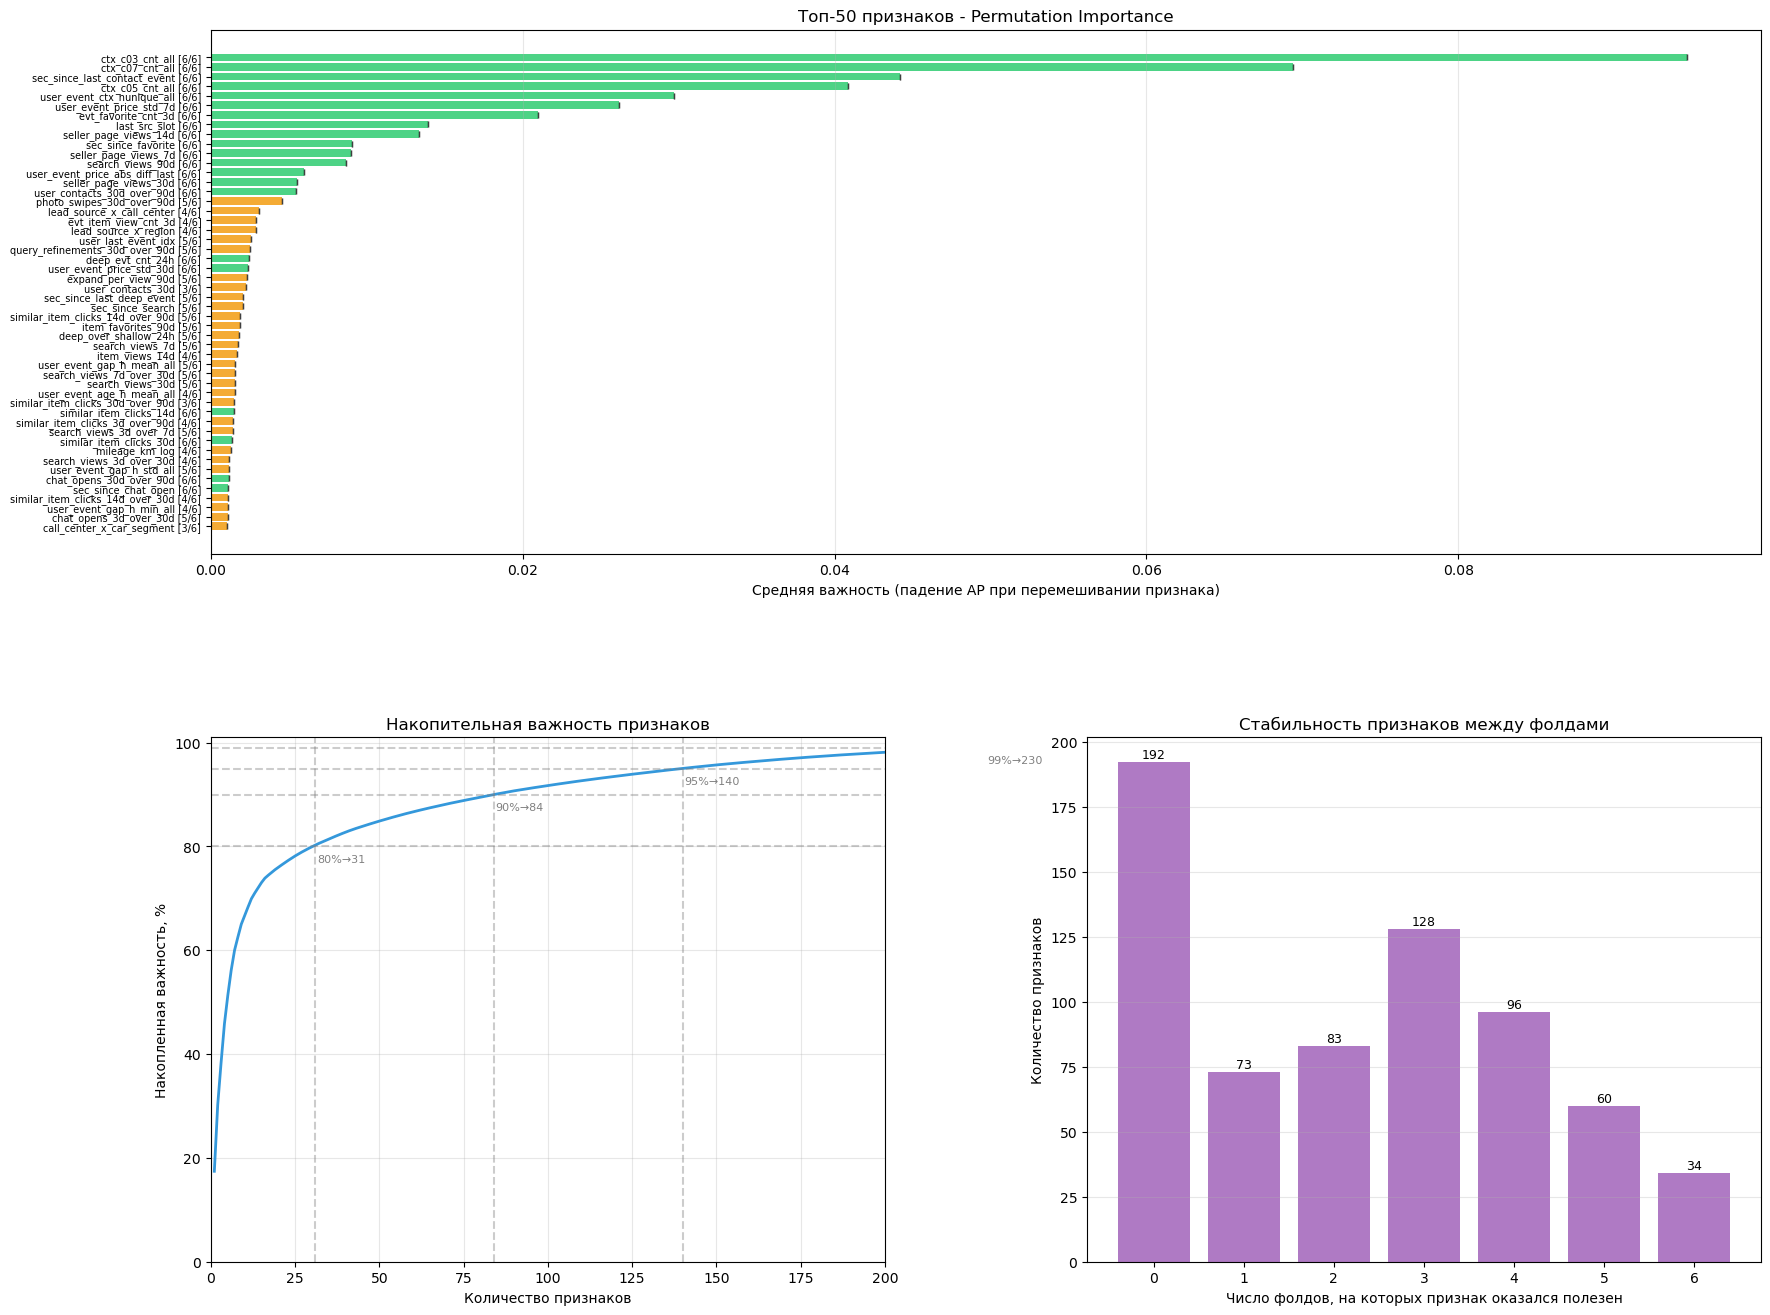


Сводка по PERMUTATION IMPORTANCE
  80% - top 31 features
  90% - top 84 features
  95% - top 140 features
  99% - top 230 features


In [ ]:
def plot_importances(imp_df, folds, top_n=50):
    n_folds = len(folds)
    fig = plt.figure(figsize=(20, 16))
    gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.3)

    # top-N признаков
    ax1  = fig.add_subplot(gs[0, :])
    top  = imp_df.head(top_n)
    colors = [
        "#2ecc71" if r["n_folds_positive"] == n_folds
        else "#f39c12" if r["n_folds_positive"] >= n_folds // 2
        else "#e74c3c"
        for _, r in top.iterrows()
    ]
    ax1.barh(range(top_n-1, -1, -1), top["gain_mean"].values, color=colors, alpha=0.85)
    ax1.errorbar(top["gain_mean"].values, range(top_n-1, -1, -1),
                 xerr=top["repeat_std_mean"].values,
                 fmt="none", color="black", alpha=0.5, capsize=2, linewidth=0.8)
    ax1.axvline(0, color="gray", linestyle="--", alpha=0.5)
    ax1.set_yticks(range(top_n-1, -1, -1))
    ax1.set_yticklabels(
        [f"{r['feature']} [{int(r['n_folds_positive'])}/{n_folds}]" for _, r in top.iterrows()],
        fontsize=7)
    ax1.set_xlabel("Средняя важность (падение AP при перемешивании признака)")
    ax1.set_title(f"Топ-{top_n} признаков - Permutation Importance")
    ax1.grid(alpha=0.3, axis="x")

    # Накопительная сумма по средней важности
    ax2    = fig.add_subplot(gs[1, 0])
    pos_df = imp_df[imp_df["gain_mean"] > 0]
    cumsum = pos_df["gain_pct"].cumsum().values
    ax2.plot(range(1, len(cumsum)+1), cumsum, color="#3498db", linewidth=2)
    for thr in [80, 90, 95, 99]:
        if cumsum[-1] >= thr:
            n = int(np.searchsorted(cumsum, thr)) + 1
            ax2.axhline(thr, color="gray", linestyle="--", alpha=0.4)
            ax2.axvline(n,   color="gray", linestyle="--", alpha=0.4)
            ax2.text(n+.5, thr-3, f"{thr}%→{n}", fontsize=8, color="gray")
    ax2.set(xlabel="Количество признаков", ylabel="Накопленная важность, %",
            title="Накопительная важность признаков", xlim=(0, min(200, len(cumsum))), ylim=(0, 101))
    ax2.grid(alpha=0.3)

    # Количество стабильных на фолдах
    ax3 = fig.add_subplot(gs[1, 1])
    vc  = imp_df["n_folds_positive"].value_counts().sort_index()
    bars = ax3.bar(vc.index, vc.values, color="#9b59b6", alpha=0.8)
    for b, v in zip(bars, vc.values):
        ax3.text(b.get_x()+b.get_width()/2, b.get_height()+.3, str(v),
                 ha="center", va="bottom", fontsize=9)
    ax3.set(xlabel="Число фолдов, на которых признак оказался полезен",
            ylabel="Количество признаков", title="Стабильность признаков между фолдами",
            xticks=range(n_folds+1))
    ax3.grid(alpha=0.3, axis="y")

    plt.savefig(RESULTS_DIR / "feature_importance.png", dpi=150, bbox_inches="tight")
    plt.show()


    print("\nСводка по PERMUTATION IMPORTANCE")
    for thr in [80, 90, 95, 99]:
        if len(cumsum) and cumsum[-1] >= thr:
            print(f"  {thr}% - top {int(np.searchsorted(cumsum,thr))+1} features")

plot_importances(imp_df, folds, top_n=50)

## Итоги по графику permutation importance

**Топ признаков и их характер**

В самом верху рейтинга находятся признаки, связанные с поведением пользователя и контекстом события из events, что и подтверждало догадки из EDA.


**Стабильность признаков**

Тут можно увидеть что самые важные признаки были полезны на всех фолдах, а менее важные не всегда, что говорит о надежности признака при разных данных

**Накопленная важность**

График cumulative importance показывает очень концентрированное распределение:
- 80% важности дают всего **20 признаков**
- 90% важности — **52 признака**
- 95% важности — **101 признак**
- 99% важности — **199 признаков**

Это значит, что боольшая часть сигнала сосредоточена в очень небольшом ядре фичей, а остальные признаки в основном дублируют информацию или добавляют шум.

**Стабильность по фолдам**

Правый график показывает, что из всех признаков:
- **286** вообще не дают положительного вклада ни на одном фолде — их можно смело удалять
- **115** полезны только на 1 фолде — скорее всего случайные всплески из за структуры фолда.
- только **22** признака полезны на всех 6 фолдах — это самое надёжные признаки
- ещё **45** полезны на 5 фолдах — тоже стабильные

## 10. Отбор признаков и сравнение подмножеств

После расчёта важности в этом блоке формируются разные наборы признаков и сравниваются между собой.

Функция `select_features` умеет выбирать признаки несколькими способами:
- по накопленной важности, например до 90% или 95%
- по top-N
- по числу фолдов, где признак был полезен
- все признаки с положительной важностью

В конце выбирается лучшее подмножество признаков, которое пойдёт дальше в HPO и финальное обучение.

In [ ]:
def select_features(imp_df, strategy="gain_pct", threshold=95):
    """Выбор стратегии отбора фич"""
    neg = set(imp_df[imp_df["gain_mean"] < 0]["feature"])
    pos = imp_df[imp_df["gain_mean"] > 0]

    if strategy == "gain_pct":
        n = int(np.searchsorted(pos["gain_pct"].cumsum().values, threshold)) + 1
        sel = pos.head(n)["feature"].tolist()
    elif strategy == "top_n":
        sel = pos.head(threshold)["feature"].tolist()
    elif strategy == "min_folds":
        sel = imp_df[(imp_df["n_folds_positive"] >= threshold) &
                     (imp_df["gain_mean"] > 0)]["feature"].tolist()
    elif strategy == "nonzero":
        sel = pos["feature"].tolist()
    else:
        raise ValueError(strategy)

    print(f"  {strategy}={threshold}: {len(sel)} features  ({len(neg)} negative dropped)")
    return sel


n_folds = len(folds)
subsets = {
    "all_features":     [c for c in train_fe.columns if c not in _SKIP_COLS],
    "gain_pct_95":      select_features(imp_df, "gain_pct", 95),
    "gain_pct_90":      select_features(imp_df, "gain_pct", 90),
    "top100":           select_features(imp_df, "top_n", 100),
    "stable_all_folds": select_features(imp_df, "min_folds", n_folds),
    "nonzero":          select_features(imp_df, "nonzero"),
}


def compare_subsets(subsets, params, train_fe, folds):
    """Сравнение разных множеств признаков"""
    print("\nСводка")
    results = {}

    for name, features in subsets.items():
        fold_scores = []
        for fold_num, (tr_idx, va_idx) in enumerate(folds, 1):
            tr = train_fe.iloc[tr_idx].reset_index(drop=True)
            va = train_fe.iloc[va_idx].reset_index(drop=True)
            
            use = [c for c in features if c in tr.columns and c in va.columns]
            cats = [c for c in use if tr[c].dtype == "object"]
            
            tr_l, va_l = _lgbm_data(tr, va, use, cats)
            w = make_sample_weights(tr)
            
            model = lgb.LGBMClassifier(**params, random_state=RANDOM_STATE)
            model.fit(tr_l, tr[TARGET], sample_weight=w,
                      eval_set=[(va_l, va[TARGET])], categorical_feature=cats,
                      callbacks=[lgb.early_stopping(50, verbose=False),
                                  lgb.log_evaluation(-1)])
            
            fold_scores.append(calculate_daily_ap(va, model.predict_proba(va_l)[:, 1]))

        m, s = float(np.mean(fold_scores)), float(np.std(fold_scores))
        results[name] = {"mean": m, "std": s, "folds": fold_scores}
        print(f"  {name:22s}: {m:.5f} ± {s:.5f}  "
              f"[{' | '.join(f'{x:.4f}' for x in fold_scores)}]  n={len(features)}")
    return results


subset_results = compare_subsets(subsets, MODELS["LightGBM"][1], train_fe, folds)
best_subset_name = max(subset_results, key=lambda k: subset_results[k]["mean"])
best_subset_features = subsets[best_subset_name]
print(f"\nBest: {best_subset_name}  AP={subset_results[best_subset_name]['mean']:.5f}  "
      f"n={len(best_subset_features)}")

  gain_pct=95: 140 features  (162 negative dropped)
  gain_pct=90: 84 features  (162 negative dropped)
  top_n=100: 100 features  (162 negative dropped)
  min_folds=6: 34 features  (162 negative dropped)
  nonzero=95: 342 features  (162 negative dropped)

Сводка
  all_features          : 0.70028 ± 0.02574  [0.7057 | 0.6808 | 0.7469 | 0.6989 | 0.6635 | 0.7060]  n=666
  gain_pct_95           : 0.70674 ± 0.02949  [0.7168 | 0.6658 | 0.7500 | 0.6929 | 0.6813 | 0.7337]  n=140
  gain_pct_90           : 0.71180 ± 0.02354  [0.7348 | 0.6753 | 0.7428 | 0.7142 | 0.6897 | 0.7140]  n=84
  top100                : 0.70878 ± 0.01861  [0.7244 | 0.6802 | 0.7387 | 0.7036 | 0.7066 | 0.6992]  n=100
  stable_all_folds      : 0.67501 ± 0.02860  [0.6919 | 0.6391 | 0.7219 | 0.6674 | 0.6440 | 0.6858]  n=34
  nonzero               : 0.70251 ± 0.02481  [0.7132 | 0.6814 | 0.7513 | 0.6890 | 0.6786 | 0.7015]  n=342

Best: gain_pct_90  AP=0.71180  n=84


Baseline на всех 744 фичах даёт **0.6923**, а лучший вариант с 100 признаками — **0.7178**. Это подтверждает, что большая часть исходных фичей — шум, который только мешает модели.

Финальный набор для HPO и обучения — **top100** с качеством **0.71781 +- 0.01887**. Он даёт лучшее качество, наибольшую стабильность и разумный размер. Именно этот набор передаётся дальше в Optuna и в финальную модель.

## 11. HPO для LightGBM через Optuna

В этом блоке запускается подбор гиперпараметров для LightGBM на лучшем наборе признаков.

Подбираются параметры, которые влияют на сложность модели, регуляризацию, sampling и структуру деревьев. Поиск идёт не на одном split, а на всей временной кросс-валидации, поэтому результат получается более надёжным.

In [ ]:
def lgbm_objective(trial, train_fe, folds, features):
    subsample = trial.suggest_float("subsample", 0.5, 1.0)
    
    # Задаем параметры подбора
    params = dict(
        objective         = "binary",
        metric            = "average_precision",
        boosting_type     = "gbdt",
        n_estimators      = trial.suggest_int("n_estimators", 300, 3000, step=100),
        learning_rate     = trial.suggest_float("learning_rate", 1e-2, 0.2, log=True),
        num_leaves        = trial.suggest_int("num_leaves", 8, 512),
        max_depth         = trial.suggest_int("max_depth", 3, 7),
        min_child_samples = trial.suggest_int("min_child_samples", 5, 200),
        min_child_weight  = trial.suggest_float("min_child_weight", 1e-4, 10.0, log=True),
        subsample         = subsample,
        subsample_freq    = 0 if subsample == 1.0 else trial.suggest_int("subsample_freq", 1, 10),
        colsample_bytree  = trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_alpha         = trial.suggest_float("reg_alpha",  1e-8, 10.0, log=True),
        reg_lambda        = trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        min_split_gain    = trial.suggest_float("min_split_gain", 0.0, 1.0),
        max_bin           = trial.suggest_int("max_bin", 64, 512, step=32),
        verbose           = -1,
    )

    fold_scores = []
    for fold_num, (tr_idx, va_idx) in enumerate(folds):
        tr = train_fe.iloc[tr_idx].reset_index(drop=True)
        va = train_fe.iloc[va_idx].reset_index(drop=True)
        
        use  = [c for c in features if c in tr.columns and c in va.columns]
        cats = [c for c in use if tr[c].dtype == "object"]
        
        tr_l, va_l = _lgbm_data(tr, va, use, cats)
        w = make_sample_weights(tr)

        model = lgb.LGBMClassifier(**params, random_state=RANDOM_STATE)
        model.fit(tr_l, tr[TARGET], sample_weight=w,
                  categorical_feature=cats,
                  callbacks=[lgb.log_evaluation(-1)])

        fold_scores.append(calculate_daily_ap(va, model.predict_proba(va_l)[:, 1]))
        trial.report(np.mean(fold_scores), step=fold_num)
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

    return float(np.mean(fold_scores))


study = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=RANDOM_STATE, n_startup_trials=10, multivariate=True),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=2),
)
study.optimize(
    lambda t: lgbm_objective(t, train_fe, folds, best_subset_features),
    n_trials=100, show_progress_bar=True, gc_after_trial=True,
)
print(f"\nHPO best: {study.best_value:.6f}")
for k, v in study.best_params.items():
    print(f"  {k:30s} = {v}")

  0%|          | 0/100 [00:00<?, ?it/s]


HPO best: 0.718934
  subsample                      = 0.9526234606850846
  n_estimators                   = 1500
  learning_rate                  = 0.016677621996818753
  num_leaves                     = 165
  max_depth                      = 7
  min_child_samples              = 16
  min_child_weight               = 0.09989364380471238
  subsample_freq                 = 2
  colsample_bytree               = 0.6425987321502823
  reg_alpha                      = 0.029444331585579332
  reg_lambda                     = 0.04634129972937858
  min_split_gain                 = 0.3702407688374274
  max_bin                        = 128


После Optuna тоже заметен прирост на 0.01. Немного, но если нужно качество это необходимо сделать

In [ ]:
def build_final_params(best_params):
    p = best_params
    return dict(
        objective         = "binary",
        metric            = "average_precision",
        boosting_type     = "gbdt",
        n_estimators      = p.get("n_estimators", 500),
        learning_rate     = p.get("learning_rate", 0.05),
        num_leaves        = p.get("num_leaves", 64),
        max_depth         = p.get("max_depth", 6),
        min_child_samples = p.get("min_child_samples", 20),
        min_child_weight  = p.get("min_child_weight", 1e-3),
        subsample         = p.get("subsample", 0.8),
        subsample_freq    = p.get("subsample_freq", 0),
        colsample_bytree  = p.get("colsample_bytree", 0.8),
        reg_alpha         = p.get("reg_alpha", 1e-5),
        reg_lambda        = p.get("reg_lambda", 1e-5),
        min_split_gain    = p.get("min_split_gain", 0.0),
        max_bin           = p.get("max_bin", 255),
        verbose           = -1,
    )

FINAL_LGBM_PARAMS = build_final_params(study.best_params)

## 12. Финальное обучение и submission

В этом блоке обучается финальная модель на полном train и строятся предсказания для test.


После этого сырые вероятности преобразуются в ранги внутри дня через `day_rank`. Затем собирается таблица `submission` с двумя колонками: `lead_id` и `score`.

In [ ]:
def final_predict(params, features, train_fe, test_fe, seeds=(42,52)):
    """TОбучение на всем датасете и ансамблирование"""
    use  = [c for c in features if c in train_fe.columns and c in test_fe.columns]
    cats = [c for c in use if train_fe[c].dtype == "object"]
    w    = make_sample_weights(train_fe)

    tr_l = train_fe[use].copy()
    te_l = test_fe[use].copy()
    for c in cats:
        tr_l[c] = tr_l[c].astype("category")
        te_l[c] = te_l[c].astype("category")

    preds = []
    for seed in seeds:
        model = lgb.LGBMClassifier(**params, random_state=seed)
        model.fit(tr_l, train_fe[TARGET], sample_weight=w,
                  categorical_feature=cats,
                  callbacks=[lgb.log_evaluation(-1)])
        preds.append(model.predict_proba(te_l)[:, 1])

    return np.mean(preds, axis=0)


print("Final training")
test_pred = final_predict(FINAL_LGBM_PARAMS, best_subset_features, train_fe, test_fe)
test_score = day_rank(test_pred, test_fe["assignment_date"])

submission = pd.DataFrame({
    "lead_id": test_fe["lead_id"].astype(str),
    "score":   test_score.astype(float),
})
assert list(submission.columns) == ["lead_id", "score"]
assert submission["lead_id"].is_unique
assert submission["score"].between(0, 1).all()

submission.to_csv(ROOT / "submission.csv", index=False)
print(f"submission.csv  {submission.shape}")

Final training
submission.csv  (4306, 2)


## 14. Сохранение всего

В последнем блоке сохраняются все результаты работы ноутбука.

Сохраняются:
- OOF-предсказания всех моделей
- информация о выбранном наборе признаков
- результаты HPO и все trial
- pickle-файл со study
- финальные параметры LightGBM
- итоговая сводка по эксперименту

После этого в папках `results` и `processed` остаются все основные параметры, чтобы можно было быстро вернуться к результатам, не пересчитывая всё заново.

In [ ]:
# OOF
oof_df = train_fe[["lead_id", "assignment_date", TARGET]].copy()
for name, oof in oof_predictions.items():
    oof_df[f"oof_{name}"] = oof
oof_df.to_csv(RESULTS_DIR / "oof_predictions.csv", index=False)

# Feature selection meta
with open(PROCESSED_DIR / "feature_selection.json", "w") as f:
    json.dump({
        "best_subset_name":     best_subset_name,
        "best_subset_features": best_subset_features,
        "n_features":           len(best_subset_features),
        "subsets_compared": {
            k: {"mean": v["mean"], "std": v["std"],
                "n": len(subsets[k]), "folds": v["folds"]}
            for k, v in subset_results.items()
        },
    }, f, indent=2)

# HPO
with open(RESULTS_DIR / "hpo_meta.json", "w") as f:
    json.dump({
        "best_value":   float(study.best_value),
        "best_trial":   study.best_trial.number,
        "best_params":  study.best_params,
        "n_trials":     len(study.trials),
        "completed":    sum(t.state == optuna.trial.TrialState.COMPLETE for t in study.trials),
        "pruned":       sum(t.state == optuna.trial.TrialState.PRUNED   for t in study.trials),
        "n_features":   len(best_subset_features),
    }, f, indent=2)
study.trials_dataframe().to_csv(RESULTS_DIR / "hpo_trials.csv", index=False)
with open(RESULTS_DIR / "hpo_study.pkl", "wb") as f:
    pickle.dump(study, f)

# Final params
with open(RESULTS_DIR / "final_lgbm_params.json", "w") as f:
    json.dump(FINAL_LGBM_PARAMS, f, indent=2)

# Summary
summary = {
    "hpo_best_ap":        float(study.best_value),
    "best_subset":        best_subset_name,
    "n_features_final":   len(best_subset_features),
    "best_baseline_model": comparison_df.index[0],
    "best_baseline_ap":   float(comparison_df.iloc[0]["mean_ap"]),
}
with open(RESULTS_DIR / "summary.json", "w") as f:
    json.dump(summary, f, indent=2)



`Подводя итоги`: был произведен EDA, обработка пропусков, категорий и Feature engineering (+600 признаков). Обучена модель LGBM, произведен Feature selection с помощью permutation importance, повысив результат и сократив кол-во признаков до 100. Был произведен подбор гиперпараметров и в итоге на валидации `Daily AP = 0.72`

Модель использует исходные табличные признаки, циклические признаки времени, дополнительные производные (last, mean, min, max, std, "/") из окон и других фич, агрегаты из `events.csv`. События фильтруются условием `event_ts < assignment_ts` до любой агрегации.

Основная модель — LGBM. Самый первый Baseline, предоставленный разработчиками на val дал 0.49, после перехода на дерево результат стал 0.54, далее был произведен FE, но без некоторых признаков из events, что дало примерно 0.65 с optuna. Feature selection также дал прирост на 0.01 на этом этапе, но более расширенное EDA, которое показало важность ctx_seq признаков, помогло повысить метрику до текущего состояния. Финальным ответом это ансамбль с разными сидами, чтобы уменьшить variance.
